# F03.02 · Línea base: lo que se consigue sin red neuronal

![Portada del notebook F03.02](img/portada_notebook_02.png)

> 🧭 **En 30 segundos**
> - **Para qué:** antes de construir la red (F03.04), ver qué nota se saca con **modelos clásicos** y sencillos. Esa nota es el **suelo**: si la red no lo supera, algo falla.
> - **Entra:** los paquetes de ventanas de **F03.01** (solo 🔵 train y 🟡 dev) → **Sale:** dos modelos entrenados, su nota en 🟡 dev (global, por paciente y por grupo de crisis), qué bandas y canales usan para decidir y una **comprobación** de que la cadena de datos funciona (detectar la crisis, §9).
> - **Idea clave:** un modelo clásico no ve la onda, ve **110 números** por ventana (cómo se reparte la energía entre las bandas del EEG). Por eso, si algo funciona, se puede decir **qué** banda y **qué** canal.
> - **Otra idea clave (§6): la AUC por paciente.** La nota global puede engañar si el modelo solo reconoce **quién** tiene muchas crisis; la nota dentro de cada paciente dice si reconoce **cuándo** llega una. Es la que importa en una app y la que decide la escalera de F03.05.

> 📍 **Dónde estamos: Fase 3 · notebook 2 (F03.02).** F03.01 dejó las ventanas listas en paquetes. Aquí se usan por primera vez para **predecir**. Lo que salió aquí **cambió el plan de la fase**: antes de la red se añadió F03.03 (contexto y normalización por paciente), y la red neuronal pasó a ser **F03.04** (ver §13).

> 🔄 **Es dinámico.** Lee lo que dejó F03.01 (conjunto, ventanas, semilla) y todas las cifras y conclusiones salen de los datos al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Todo (modelo, hiperparámetros, variante) se elige con 🟡 dev. Eval y los controles de F02.05 se usan **una sola vez**, al final de la fase, con el modelo cerrado. Si se mirara antes, la nota final dejaría de ser honesta.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Antes de fichar a un jugador carísimo, un entrenador mira qué consigue con los que ya tiene. Aquí pasa lo mismo: antes de construir una **red neuronal** (cara de entrenar y difícil de explicar), se mira qué consiguen **modelos clásicos** y baratos con la misma información. Esa nota es el **suelo**: la red tiene que superarlo, o no aporta nada.

El notebook responde a **dos preguntas**:

| Pregunta | Dónde se responde | Por qué importa |
|---|---|---|
| ¿Cuánto se predice con una ventana de 4 s sola y modelos clásicos? | §5 a §8 | Es el suelo de la red |
| Si sale mal, ¿es que los datos fallan o que predecir es difícil? | §9 (comprobación con la detección) | Decide si hay que revisar la Fase 2 o cambiar de estrategia |

![La historia de la Fase 3, con F03.02 destacado](img/historia_fase_03_nb02.png)

👀 **Qué enseña.** Las preguntas de toda la fase, en orden, y lo que salió. El recuadro rojo marca **dónde estás**; el resto de la fase sale atenuado. Este notebook ocupa las filas 2 y 3: la línea base salió **casi el azar** y la comprobación demostró que **los datos están bien**. Esa combinación es la que llevó a F03.03.

## El recorrido de este notebook

![El recorrido del notebook F03.02](img/mapa_notebook_02.png)

👀 **Qué enseña.** Los seis pasos, en orden. Cada caja es una sección (§). Los dos en rojo son los más importantes: la **nota en dev** (§5) y la **nota por paciente** (§6), que dice si el modelo distingue de verdad las ventanas o solo reconoce a los pacientes.

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Línea base** | El resultado de un método sencillo, con el que se compara el método nuevo. Si la red no lo mejora, no aporta nada |
| **Característica** | Un número que resume algo de la ventana (aquí, cuánta energía hay en una banda de un canal). El modelo clásico ve estos números, no la onda |
| **Espectro / FFT / Welch** | El espectro dice cuánta energía hay en cada frecuencia. La FFT lo calcula; Welch la hace sobre trozos de 1 s y los promedia, para que salga más estable |
| **Banda** | Un rango de frecuencias del EEG: delta (0,5-4 Hz), theta (4-8), alfa (8-13), beta (13-30) y gamma (30-45) |
| **Potencia relativa** | La energía de una banda dividida por la de todas: qué **parte** de la energía está en esa banda. No cambia si la señal se mide más fuerte o más flojo |
| **Regresión logística** | Un modelo que suma las características, cada una con un peso, y pasa el resultado a 0-1 con una curva en S. Ver §4 |
| **XGBoost** | Muchos árboles de decisión pequeños; cada uno corrige los errores de los anteriores. Ver §4 |
| **Hiperparámetro** | Un "botón" del modelo que no se aprende de los datos y se elige probando (p. ej. cuánto se frenan los pesos). Se elige con 🟡 dev |
| **Puntuación** | Lo que devuelve el modelo para cada ventana, de 0 a 1: más alta = más probable ⏳ preictal |
| **AUC-ROC** | La nota: elegida una ⏳ y una 💤 al azar, la probabilidad de que la ⏳ puntúe más. 0,5 = azar, 1 = perfecto. No depende de cuántas haya de cada clase. Ver §5 |
| **Curva ROC** | Cómo cambian a la vez los aciertos en ⏳ (sensibilidad) y las falsas alarmas en 💤 al mover el umbral. La AUC es el área bajo esta curva |
| **Sensibilidad / especificidad** | Qué parte de las ⏳ se detectan / qué parte de las 💤 se dejan tranquilas |
| **Umbral** | El valor de puntuación a partir del cual se dice "⏳ preictal" |
| **Intervalo de confianza (IC 95 %)** | Entre qué valores estaría la nota con otros pacientes parecidos. Se calcula sorteando **pacientes** (bootstrap por paciente), porque las ventanas de un paciente se parecen mucho |
| **AUC por paciente** | La AUC calculada solo con las ventanas de un paciente. Mide si el modelo ordena bien **dentro** de cada paciente. Ver §6 |
| **Mismo peso por paciente** | Variante de entrenamiento en la que cada paciente cuenta lo mismo, tenga muchas o pocas ventanas (F03.01 §3.1) |
| **Sobreajuste** | Que el modelo memorice los pacientes de entrenamiento y falle con pacientes nuevos |

## 0. El parámetro: qué conjunto se usa

El mismo que en F03.01: **`general`** es el modelo principal. Tiene que existir su paquete (ejecutar antes F03.01 con el mismo `CONJUNTO`).

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill cambiando solo este valor.)*

> **`CONJUNTO` se fija en un solo sitio para toda la Fase 3:** `tfm_comun/prediccion/estudio.py` (`CONJUNTO_ESTUDIO`). Aquí se deja en `None`; solo se pone otro valor para una prueba puntual (o desde papermill). Los resultados de cada conjunto van a su carpeta: `outputs/fase_03/<conjunto>/`.

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar que están instaladas las librerías (las que falten se instalan solas).
>
> 🤔 **Por qué:** aparecen dos nuevas en el TFM: **scikit-learn** ya se usó en F02.05, y **XGBoost** es nueva. Aquí no hace falta PyTorch ni la GPU: los modelos clásicos entrenan en segundos en el procesador.

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_LINEA_BASE
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_LINEA_BASE)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características


Todo lo necesario está instalado.


In [3]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado)
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

# Librerías de siempre
import json
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import xgboost
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# tfm_comun: rutas, señal y paquetes
from tfm_comun.entorno.rutas import RUTA_OUTPUTS, RUTA_OUTPUTS_FASE_02, RUTA_OUTPUTS_FASE_03, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.senal.bandas import BANDAS_HZ
from tfm_comun.senal.montaje import CADENAS_TCP, CANALES_TCP
from tfm_comun.red.paquetes import cargar_paquete, crear_paquete, paquete_al_dia

# tfm_comun: características, modelos clásicos y su evaluación
from tfm_comun.prediccion.caracteristicas import SEGMENTO_S, nombres_caracteristicas, caracteristicas_por_trozos
from tfm_comun.prediccion.almacen_caracteristicas import (rutas_caracteristicas, caracteristicas_al_dia,
                                                          guardar_caracteristicas, cargar_caracteristicas)
from tfm_comun.prediccion.validacion import rondas_validacion
from tfm_comun.prediccion.linea_base import (NOMBRES_MODELO, REJILLAS, VARIANTES_PESO, combinaciones,
                                             entrenar, puntuar, pesos_explicativos)
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo, muestras_auroc_bootstrap
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente
from tfm_comun.prediccion.evaluacion.sensibilidad import sensibilidad_con_especificidad

# tfm_comun: cómo se enseñan las cosas (iconos, colores, números, tablas, ficheros, letra)
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos
from tfm_comun.visual.colores import COLORES_PERIODO, COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, xgboost)

# El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
xgboost     3.4.1


✅ **Qué deberías ver:** en la tabla de librerías, todas con ✅ (o 🆕 si se acaban de instalar), y debajo la versión de cada una.

## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook y leer lo que dejó F03.01.
>
> 🤔 **Por qué:** no hay que copiar a mano ninguna cifra: el tamaño de la ventana, la semilla y los paquetes salen de `outputs/fase_03/01_datos_red/configuracion.json`.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `MODELOS` | `['logistica', 'xgboost']` | Los dos modelos clásicos (§4) |
| `VARIANTES` | `['normal', 'mismo_peso_paciente']` | Cada modelo se entrena dos veces: con todas las ventanas pesando igual y con todos los **pacientes** pesando igual (§4) |
| `ESPECIFICIDAD` | 0,9 | Para dar un punto de la curva ROC que se entienda: la sensibilidad cuando solo se permite dar falsa alarma en el 10 % de las 💤 (§5) |
| `N_BOOTSTRAP` | 500 | Sorteos de pacientes para el intervalo de confianza (§5) |
| `N_EJEMPLO` | 2.000 | Ventanas de cada clase con las que se dibuja la figura de las bandas (§3) |

Los hiperparámetros que se prueban de cada modelo están en `tfm_comun/prediccion/modelos/` (`REJILLA` de cada modelo, reunidas en `REJILLAS` de `linea_base.py`): son pocos a propósito, porque la línea base tiene que ser **sencilla**.

In [4]:
MODELOS = ['logistica', 'xgboost']
VARIANTES = ['normal', 'mismo_peso_paciente']
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
N_EJEMPLO = 2000

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">CONJUNTO</code> · qué conjunto de ventanas se estudia (<code>general</code> = el modelo principal) <i style="color:#4d4d4d">(§0, completado en §1)</i></li></ul></div>

In [5]:
# 1) Carpeta de resultados de este notebook (una por conjunto)
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/02_linea_base')

# 2) Leer lo que dejó F03.01 y comprobar que es del mismo conjunto
ruta_config_01 = RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json'
assert ruta_config_01.exists(), f'No encuentro {ruta_config_01}. Ejecuta antes F03.01 (fase_03/01_datos_red.ipynb).'

config_01 = json.loads(ruta_config_01.read_text(encoding='utf-8'))
assert config_01['conjunto'] == CONJUNTO, (
    f'F03.01 se ejecutó con CONJUNTO = {config_01["conjunto"]!r} y aquí es {CONJUNTO!r}: '
    'ejecuta F03.01 con el mismo conjunto.')

# 3) Las cifras que manda F03.01 (no se copian a mano)
SEMILLA = int(config_01['semilla'])
VENTANA_S = config_01['ventana_s']
MUESTRAS = int(config_01['muestras_por_ventana'])
FS = MUESTRAS / VENTANA_S                                                  # muestras por segundo (256 Hz)
SPLITS = [s for s in ['train', 'dev'] if s in config_01['paquetes']]      # 🟢 eval NO se usa aquí
NOMBRES = nombres_caracteristicas(CANALES_TCP)
BANDAS = list(BANDAS_HZ)

# 4) Resumen
aviso_prueba = '  ·  ⚠️ MODO PRUEBA: F03.01 se ejecutó con datos incompletos' if config_01.get('modo_prueba') else ''
print(f'Conjunto: {CONJUNTO} · ventanas de {VENTANA_S} s a {numero_legible(FS)} Hz · {len(NOMBRES)} características '
      f'({len(CANALES_TCP)} canales × {len(BANDAS)} bandas) · semilla {SEMILLA}' + aviso_prueba)
print(f'Paquetes que se usan: {", ".join(con_icono(s) for s in SPLITS)}  ·  🟢 eval no se abre en este notebook')

Conjunto: general · ventanas de 4 s a 256 Hz · 110 características (22 canales × 5 bandas) · semilla 42
Paquetes que se usan: 🔵 train, 🟡 dev  ·  🟢 eval no se abre en este notebook


## 3. Características: de cada ventana, 110 números

> 🎯 **Qué hacemos:** resumir cada ventana (22 canales × 1.024 muestras) en **110 números**: qué parte de la energía de cada canal cae en cada banda del EEG.
>
> 🤔 **Por qué:** los modelos clásicos no saben mirar una onda; necesitan una tabla de números. La **potencia por bandas** es la elección más habitual en TUSZ (log-FFT de Roy 2020 y Tang 2021, en la síntesis del estado del arte) y se entiende: "antes de una crisis sube la delta en este canal".

![De una ventana a 110 números](img/de_ventana_a_numeros.png)

👀 **Qué enseña.** Los tres pasos con una ventana: (1) la ventana, (2) el espectro de un canal con las cinco bandas marcadas y (3) qué parte de la energía cae en cada banda. Se hace en los 22 canales: 22 × 5 = 110 números. Abajo a la derecha, por qué se usa la potencia **relativa**: no cambia si el equipo mide más fuerte, así que el modelo no puede hacer trampa con el "volumen" (la pista H3 de F02.05).

> 💡 La señal viene filtrada a 0,5-40 Hz (F02.02), así que en la banda gamma (30-45 Hz) solo hay de verdad la parte de 30 a 40 Hz.

Las características se calculan **una vez** y se guardan. Si los paquetes de F03.01 no han cambiado, la siguiente ejecución las reutiliza y esta sección tarda segundos.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SPLITS</code> · las particiones que se abren aquí: 🔵 train y 🟡 dev (🟢 eval nunca) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRES</code> · los 110 nombres de las características (<code>FP1-F7 · delta</code>…), en el orden de las columnas <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">FS</code> · muestras por segundo de la señal (256) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [6]:
partes_filas, partes_X, filas_calculo = [], [], {}

for split in SPLITS:
    inicio = time.time()

    # 1) Abrir el paquete de ventanas de F03.01
    matriz, indice = cargar_paquete(CONJUNTO, split)

    # 2) Calcular las características solo si no estaban ya guardadas y al día
    if caracteristicas_al_dia(CONJUNTO, split, indice.id_ventana, len(NOMBRES)):
        estado = 'ya estaba al día'
    else:
        estado = 'calculada'
        X_split = caracteristicas_por_trozos(
            matriz, FS, progreso=lambda it, total: tqdm(it, total=total, desc=f'{split}: trozos de 2.048 ventanas'))
        guardar_caracteristicas(CONJUNTO, split, indice.id_ventana.to_numpy(), X_split)

    # 3) Leerlas del disco y comprobar que van en el orden del paquete
    X_split, ids = cargar_caracteristicas(CONJUNTO, split)
    assert (ids == indice.id_ventana.to_numpy()).all(), f'Las características de {split} no están en el orden del paquete.'

    partes_filas.append(indice)
    partes_X.append(X_split)
    filas_calculo[split] = {'estado': estado, 'ventanas': len(indice), 'características': X_split.shape[1],
                            '% de valores sin señal (NaN)': 100 * float(np.isnan(X_split).mean()),
                            'segundos': time.time() - inicio}

# 4) Juntar train + dev: una fila por ventana, en el mismo orden que X
filas = pd.concat(partes_filas, ignore_index=True)
X = np.concatenate(partes_X)
y = filas.etiqueta.to_numpy()                 # 1 = ⏳ preictal, 0 = 💤 interictal
pacientes = filas.patient.to_numpy()

# 5) Tabla del cálculo
tabla_calculo = pd.DataFrame(filas_calculo).T
tabla_calculo.index.name = 'split'
display(con_separadores(tabla_con_iconos(tabla_calculo), decimales=1))

,estado,ventanas,características,% de valores sin señal (NaN),segundos
split,,,,,
🔵 train,ya estaba al día,29.152,110,"2,6","0,1"
🟡 dev,ya estaba al día,55.879,110,"1,4","0,4"


👀 **Cómo leer la tabla.** Una fila por paquete: si las características se han **calculado** ahora o **ya estaban al día**, cuántas ventanas, cuántas características (110), qué porcentaje de valores son **NaN** y cuánto ha tardado. Los NaN son los canales sin señal: A1-T3 y T4-A2 en los ficheros sin electrodos A1/A2 (F02.02 los rellena con ceros, y un canal a cero no tiene reparto de energía). Los dos modelos saben tratarlos.

✅ **Qué deberías ver:** la primera vez, *calculada* y uno o dos minutos por paquete; las siguientes, *ya estaba al día* y segundos. El % de NaN, pequeño (por debajo del 10 %).

### 3.1 Un ejemplo con una ventana real: de la onda a los 110 números

La imagen de arriba explica el paso con un dibujo. Aquí se hace con **una ventana de verdad**, en tres tablas:

1. **La ventana en bruto:** 22 canales × 1.024 muestras, en µV (microvoltios). Es una onda.
2. **La rejilla:** 22 canales × 5 bandas, con el **% de la energía** de cada canal que cae en cada banda. Cada fila suma 100 %.
3. **La fila final:** la rejilla aplanada en **110 números** (el log10 de esos %), que es lo único que ve el modelo.

Se elige una ventana ⏳ preictal de 🔵 train al azar, pero siempre la misma (con la semilla), y sin canales vacíos.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas</code> · tabla con una fila por ventana de 🔵 train y 🟡 dev: quién es (<code>id_ventana</code>, <code>patient</code>), su clase, partición, grupo de crisis y si es de entrenamiento o de validación. Va en el mismo orden que <code>X</code> <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X</code> · matriz ventanas × 110: los 110 números de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y</code> · la etiqueta de cada ventana: 1 = ⏳ preictal, 0 = 💤 interictal <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · número que fija el azar (el mismo sorteo en cada ejecución) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MUESTRAS</code> · muestras por ventana (1.024 = 4 s × 256 Hz) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [7]:
# 1) Elegir una ventana ⏳ preictal de 🔵 train: al azar, pero siempre la misma (semilla), y sin canales vacíos
rng_ejemplo = np.random.default_rng(SEMILLA)
es_candidata = (filas.split.to_numpy() == 'train') & (y == 1) & ~np.isnan(X).any(axis=1)
pos_ejemplo = int(rng_ejemplo.choice(np.flatnonzero(es_candidata)))
ventana_ejemplo = filas.iloc[pos_ejemplo]

# 2) Leer su señal en bruto del paquete de 🔵 train
matriz_train, indice_train = cargar_paquete(CONJUNTO, 'train')
fila_paquete = int(np.flatnonzero(indice_train.id_ventana.to_numpy() == ventana_ejemplo.id_ventana)[0])
senal_ejemplo = np.asarray(matriz_train[fila_paquete], dtype=np.float32)      # 22 canales × 1.024 muestras, en µV

# 3) Tabla: los 22 canales (agrupados por cadena del montaje) y sus primeras muestras
canales_por_cadena = pd.MultiIndex.from_tuples(
    [(cadena, f'{a}-{b}') for cadena, pares in CADENAS_TCP.items() for a, b in pares],
    names=['cadena', 'canal'])
N_MUESTRAS_EJEMPLO = 6
bruto = pd.DataFrame(senal_ejemplo[:, :N_MUESTRAS_EJEMPLO], index=canales_por_cadena,
                     columns=[f'{k / FS:.3f} s'.replace('.', ',') for k in range(N_MUESTRAS_EJEMPLO)])
bruto[f'… hasta {numero_legible(MUESTRAS)} muestras'] = '…'

# 4) Mostrar
display(Markdown(f'**Ventana de ejemplo:** `{ventana_ejemplo.id_ventana}` · paciente `{ventana_ejemplo.patient}` · '
                 f'{con_icono(ventana_ejemplo.clase)} · grupo {con_icono(ventana_ejemplo.grupo)}  \n'
                 f'**① En bruto:** {len(CANALES_TCP)} canales × {numero_legible(MUESTRAS)} muestras en µV '
                 f'(aquí, las {N_MUESTRAS_EJEMPLO} primeras: los primeros {decimal(N_MUESTRAS_EJEMPLO / FS, 3)} s)'))
display(con_separadores(bruto, decimales=1))

**Ventana de ejemplo:** `aaaaacsx_s001_t000_preictal_000000000_000259090` · paciente `aaaaacsx` · ⏳ preictal · grupo ♦️ focal  
**① En bruto:** 22 canales × 1.024 muestras en µV (aquí, las 6 primeras: los primeros 0,023 s)

👀 **Cómo leer la tabla ①.** Cada fila es un canal (agrupados por la cadena del montaje, con una línea entre cadenas) y cada columna, un instante: una muestra cada 1/256 s ≈ 0,004 s. Los valores son la tensión en µV, positivos o negativos: es la **onda**. Un modelo clásico no sabe qué hacer con 22.528 números así; por eso se resumen.

In [8]:
# 1) Deshacer el logaritmo (10 ** valor) y pasarlo a %: qué parte de la energía de cada canal cae en cada banda
porcentajes = 100 * 10 ** X[pos_ejemplo]

# 2) Colocar los 110 números en su rejilla: 22 canales (filas) × 5 bandas (columnas)
rejilla_ejemplo = pd.DataFrame(porcentajes.reshape(len(CANALES_TCP), len(BANDAS)), index=canales_por_cadena, columns=BANDAS)
rejilla_ejemplo['suma'] = rejilla_ejemplo.sum(axis=1)

# 3) Mostrar
display(Markdown('**② La rejilla:** % de la energía de cada canal en cada banda (cada fila suma 100 %)'))
display(con_separadores(rejilla_ejemplo, decimales=1))

banda_mayor = rejilla_ejemplo[BANDAS].mean().idxmax()
print(f'En esta ventana, la banda que se lleva más energía (media de los 22 canales) es {banda_mayor}: '
      f'el {decimal(rejilla_ejemplo[banda_mayor].mean(), 1)} %.')

**② La rejilla:** % de la energía de cada canal en cada banda (cada fila suma 100 %)

En esta ventana, la banda que se lleva más energía (media de los 22 canales) es delta: el 49,9 %.


👀 **Cómo leer la tabla ②.** La misma ventana, resumida: cada fila es un canal y cada columna, una banda. El número es qué **parte** de la energía de ese canal está en esa banda; por eso cada fila suma 100 % (columna *suma*). Lo normal es que **delta** se lleve la parte más grande y **gamma** la más pequeña. La onda de 1.024 muestras por canal se ha quedado en 5 números por canal.

In [9]:
# La fila final: la rejilla aplanada fila a fila (canal 1 con sus 5 bandas, luego el canal 2...) y en log10
fila_ejemplo = pd.DataFrame([X[pos_ejemplo, :10]], columns=NOMBRES[:10], index=[ventana_ejemplo.id_ventana])
fila_ejemplo['…'] = f'… hasta {len(NOMBRES)} columnas'

display(Markdown('**③ La fila que ve el modelo:** los 110 números en log10 (aquí, los 10 primeros: los canales FP1-F7 y F7-T3)'))
display(con_separadores(fila_ejemplo, decimales=2))

**③ La fila que ve el modelo:** los 110 números en log10 (aquí, los 10 primeros: los canales FP1-F7 y F7-T3)

,FP1-F7 · delta,FP1-F7 · theta,FP1-F7 · alfa,FP1-F7 · beta,FP1-F7 · gamma,F7-T3 · delta,F7-T3 · theta,F7-T3 · alfa,F7-T3 · beta,F7-T3 · gamma,…
aaaaacsx_s001_t000_preictal_000000000_000259090,"-0,07","-1,12","-1,63","-1,50","-1,65","-0,28","-1,07","-1,02","-0,73","-0,98",… hasta 110 columnas


👀 **Cómo leer la tabla ③.** Es la rejilla ② puesta en **una sola fila**: primero las 5 bandas de FP1-F7, luego las 5 de F7-T3, y así hasta los 22 canales (110 columnas). Cada valor es el **log10** del % de la tabla ② dividido entre 100: por ejemplo, el 85 % → log10(0,85) ≈ −0,07 y el 10 % → −1. El logaritmo pone en una escala parecida números muy pequeños (0,1 %) y muy grandes (90 %). **Esta fila es todo lo que ve el modelo de esta ventana.**

### 3.2 Lo que se guarda en disco: el fichero y la misma tabla con nombres

Las características se guardan en un fichero `.npy`: una matriz de números **sin nombres** (filas 0, 1, 2… y columnas [0], [1], [2]…). La celda de abajo enseña primero el fichero **tal como está en disco** y después **las mismas filas con el nombre de cada columna**. La imagen explica cómo se pasa de una a otra:

![Cómo se leen las 110 columnas del fichero](img/columnas_a_nombres.png)

👀 **Qué enseña.** Cada canal ocupa **5 columnas seguidas**, una por banda (delta, theta, alfa, beta, gamma). Así, la columna [7] es la 3.ª banda (alfa) del 2.º canal (F7-T3). Es la rejilla ② de §3.1 aplanada fila a fila.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ruta del fichero</code> · se pide con <code>rutas_caracteristicas(CONJUNTO, split)</code> <i style="color:#4d4d4d">(función de tfm_comun)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X, filas</code> · los 110 números de cada ventana y quién es cada una (ver arriba) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SEMILLA</code> · fija el sorteo de los ejemplos <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [10]:
# 1) El fichero tal como está en disco: números sin nombres, sin redondear
ruta_npy, ruta_ids = rutas_caracteristicas(CONJUNTO, SPLITS[0])
mostrar_fichero(ruta_npy, f'una fila por ventana del paquete {SPLITS[0]} (mismo orden que {ruta_ids.name}) y una columna por '
                'característica: log10 de la parte de la energía de un canal que cae en una banda (0 = toda; -1 = el 10 %; -2 = el 1 %)')

# 2) Las mismas 5 primeras filas, ahora con nombre en cada columna y redondeadas a 2 decimales
mismas_filas = pd.DataFrame(X[:5, :10], columns=NOMBRES[:10], index=filas.id_ventana[:5])
mismas_filas.insert(0, 'clase', [con_icono(c) for c in filas.clase[:5]])
display(Markdown('*Las **mismas 5 filas** de arriba (la fila 0 de arriba es la primera de aquí), con el nombre de las 10 primeras '
                 'columnas (canales FP1-F7 y F7-T3, sus 5 bandas) y **redondeadas a 2 decimales** (−0,074698 → −0,07):*'))
display(con_separadores(mismas_filas, decimales=2))

if filas.clase[:5].nunique() == 1 and filas.patient[:5].nunique() == 1:
    display(Markdown(f'*Las 5 primeras son todas {con_icono(filas.clase[0])} del mismo paciente: el fichero va en el orden del paquete. '
                     'Para comparar clases, abajo hay 3 ventanas de cada una elegidas al azar.*'))

# 3) Ejemplo mixto: 3 ventanas ⏳ y 3 💤 de 🔵 train, al azar (siempre las mismas)
rng_mezcla = np.random.default_rng(SEMILLA)
en_train = filas.split.to_numpy() == 'train'
posiciones_mezcla = np.concatenate([rng_mezcla.choice(np.flatnonzero(en_train & (y == etiqueta)), 3, replace=False)
                                    for etiqueta in (1, 0)])
mezcla = pd.DataFrame(X[posiciones_mezcla, :10], columns=NOMBRES[:10],
                      index=pd.Index([con_icono(c) for c in filas.clase.to_numpy()[posiciones_mezcla]], name='clase'))
mezcla.insert(0, 'paciente', filas.patient.to_numpy()[posiciones_mezcla])
display(Markdown('*3 ventanas ⏳ preictales y 3 💤 interictales de 🔵 train, al azar:*'))
display(con_separadores(mezcla, decimales=2))

💾 **Guardado `train.npy`** · 12,8 MB · 29.152 × 110 (float32)  
*Qué guarda:* una fila por ventana del paquete train (mismo orden que train_ids.csv) y una columna por característica: log10 de la parte de la energía de un canal que cae en una banda (0 = toda; -1 = el 10 %; -2 = el 1 %). *Abajo:* las 5 primeras filas y sus 5 primeras columnas (de 110), sin redondear.

,[0],[1],[2],[3],[4]
0,-0.074698,-0.943913,-1.812325,-1.622568,-2.302614
1,-0.601622,-0.199781,-1.260144,-1.271616,-1.998551
2,-0.329734,-0.444495,-1.053312,-1.137057,-1.948665
3,-0.206686,-0.633692,-1.172984,-1.192502,-1.826686
4,-0.093502,-0.883176,-1.576893,-1.569477,-2.027172


*Las **mismas 5 filas** de arriba (la fila 0 de arriba es la primera de aquí), con el nombre de las 10 primeras columnas (canales FP1-F7 y F7-T3, sus 5 bandas) y **redondeadas a 2 decimales** (−0,074698 → −0,07):*

,clase,FP1-F7 · delta,FP1-F7 · theta,FP1-F7 · alfa,FP1-F7 · beta,FP1-F7 · gamma,F7-T3 · delta,F7-T3 · theta,F7-T3 · alfa,F7-T3 · beta,F7-T3 · gamma
id_ventana,,,,,,,,,,,
aaaaaacz_s001_t001_interictal_000000000_000005120,💤 interictal,"-0,07","-0,94","-1,81","-1,62","-2,30","-0,42","-0,35","-1,07","-1,13","-1,72"
aaaaaacz_s001_t001_interictal_000000000_000011264,💤 interictal,"-0,60","-0,20","-1,26","-1,27","-2,00","-0,65","-0,29","-1,07","-0,89","-1,27"
aaaaaacz_s001_t001_interictal_000000000_000013312,💤 interictal,"-0,33","-0,44","-1,05","-1,14","-1,95","-0,85","-0,42","-0,66","-0,72","-1,17"
aaaaaacz_s001_t001_interictal_000000000_000022528,💤 interictal,"-0,21","-0,63","-1,17","-1,19","-1,83","-0,38","-0,46","-0,95","-0,98","-1,63"
aaaaaacz_s001_t001_interictal_000000000_000026624,💤 interictal,"-0,09","-0,88","-1,58","-1,57","-2,03","-0,14","-0,96","-1,27","-1,10","-1,40"


*Las 5 primeras son todas 💤 interictal del mismo paciente: el fichero va en el orden del paquete. Para comparar clases, abajo hay 3 ventanas de cada una elegidas al azar.*

*3 ventanas ⏳ preictales y 3 💤 interictales de 🔵 train, al azar:*

,paciente,FP1-F7 · delta,FP1-F7 · theta,FP1-F7 · alfa,FP1-F7 · beta,FP1-F7 · gamma,F7-T3 · delta,F7-T3 · theta,F7-T3 · alfa,F7-T3 · beta,F7-T3 · gamma
clase,,,,,,,,,,,
⏳ preictal,aaaaaqkh,"-0,08","-1,02","-1,53","-1,38","-2,09","-0,14","-1,01","-1,04","-1,14","-1,67"
⏳ preictal,aaaaadqe,"-0,04","-1,16","-1,91","-2,09","-2,60","-0,09","-0,85","-1,58","-1,83","-2,42"
⏳ preictal,aaaaardk,"-0,23","-0,77","-1,06","-1,09","-1,12","-0,23","-1,12","-1,01","-0,91","-0,95"
💤 interictal,aaaaadqe,"-0,02","-1,61","-2,12","-2,56","-2,83","-0,11","-0,96","-1,54","-1,30","-1,50"
💤 interictal,aaaaardk,"-0,66","-0,57","-1,48","-0,64","-0,61","-0,65","-0,29","-1,11","-0,94","-1,16"
💤 interictal,aaaaartn,"-0,09","-1,05","-1,31","-1,37","-2,35","-0,08","-0,98","-1,54","-1,53","-2,42"


👀 **Cómo leer las tablas.** Las tres son los **mismos datos** vistos de distinta forma:

- **La primera** es el fichero `.npy` en bruto: filas y columnas numeradas, sin nombres y con todos los decimales. Enseña solo una esquina (5 filas × 5 columnas); arriba de la tabla pone su tamaño real (ventanas × 110).
- **La segunda** son **las mismas 5 filas** con el nombre de cada columna (*canal · banda*) y **redondeadas a 2 decimales**. Su primera fila es la fila 0 de la primera tabla.
- **La tercera** mezcla ⏳ y 💤 para comparar.

Los valores son **logaritmos** de una proporción, así que son negativos: −0,3 ≈ el 50 % de la energía del canal está en esa banda; −1 = el 10 %; −2 = el 1 %. Lo normal en EEG es que delta tenga la parte más grande (valor más cerca de 0) y gamma la más pequeña.

**¿Se ve ya alguna diferencia entre ⏳ y 💤?** En unas pocas filas no se aprecia. La figura de abajo lo mira con miles de ventanas de entrenamiento, antes de entrenar nada.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X, y, filas</code> · los 110 números, la etiqueta y quién es cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_EJEMPLO</code> · cuántas ventanas de cada clase se dibujan (2.000) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

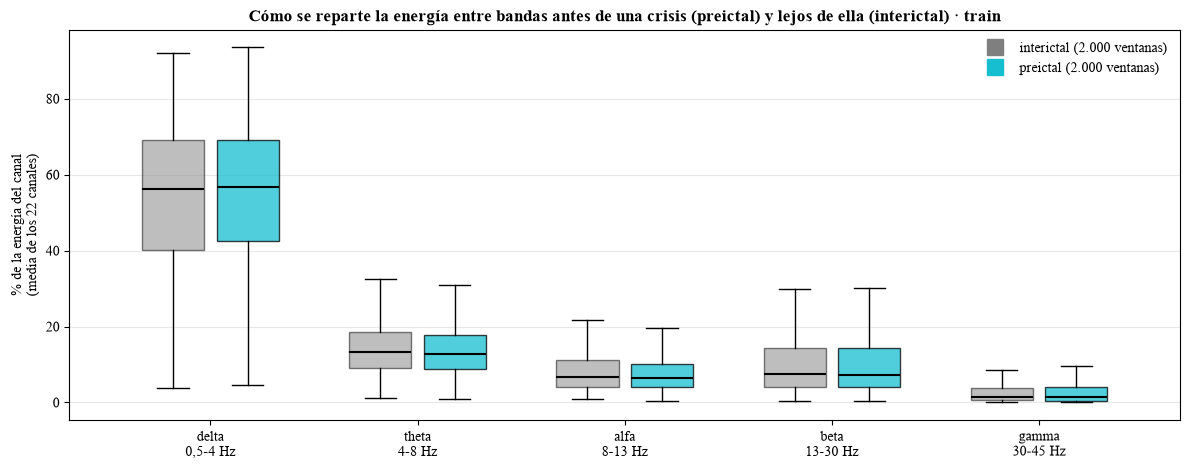

Mayor diferencia de medianas: delta (+1,2 puntos de % en ⏳ preictal respecto a 💤 interictal)


In [11]:
# 1) Preparar: media de los 22 canales de cada banda, y una muestra de ventanas de entrenamiento de cada clase
rng = np.random.default_rng(SEMILLA)
en_entrena = filas.en_entrenamiento.to_numpy(dtype=bool)
media_bandas = np.nanmean(X.reshape(len(X), len(CANALES_TCP), len(BANDAS)), axis=1)      # ventanas × bandas

# 2) Dibujar: dos cajas por banda (💤 y ⏳)
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(12, 4.8))

    for k, clase in enumerate(['interictal', 'preictal']):
        posiciones = np.flatnonzero(en_entrena & (filas.clase.to_numpy() == clase))
        posiciones = rng.choice(posiciones, size=min(N_EJEMPLO, len(posiciones)), replace=False)
        datos = [100 * 10 ** media_bandas[posiciones, b] for b in range(len(BANDAS))]

        partes = ax.boxplot(datos, positions=np.arange(len(BANDAS)) + (k - 0.5) * 0.36, widths=0.3,
                            patch_artist=True, showfliers=False, medianprops={'color': 'black', 'lw': 1.5})
        for caja in partes['boxes']:
            caja.set(facecolor=COLORES_PERIODO[clase], alpha=0.75 if clase == 'preictal' else 0.5, edgecolor='black')
        ax.plot([], [], 's', color=COLORES_PERIODO[clase], ms=12, label=f'{clase} ({numero_legible(len(posiciones))} ventanas)')

    # 3) Rotular y guardar
    ax.set_xticks(range(len(BANDAS)), [f'{b}\n{numero_legible(a)}-{numero_legible(z)} Hz' for b, (a, z) in BANDAS_HZ.items()])
    ax.set_ylabel('% de la energía del canal\n(media de los 22 canales)')
    ax.set_title('Cómo se reparte la energía entre bandas antes de una crisis (preictal) y lejos de ella (interictal) · train',
                 fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'bandas_preictal_interictal.png', dpi=150, bbox_inches='tight')
    plt.show()

# 4) La banda con más diferencia entre clases
diferencias = {b: float(np.median(100 * 10 ** media_bandas[en_entrena & (y == 1), j])
                        - np.median(100 * 10 ** media_bandas[en_entrena & (y == 0), j]))
               for j, b in enumerate(BANDAS)}
mayor = max(diferencias, key=lambda b: abs(diferencias[b]))
print(f'Mayor diferencia de medianas: {mayor} ({"+" if diferencias[mayor] > 0 else ""}{decimal(diferencias[mayor], 1)} '
      'puntos de % en ⏳ preictal respecto a 💤 interictal)')

👀 **Cómo leer la figura.** Para cada banda, dos cajas: 💤 interictal (gris) y ⏳ preictal (azul claro). Cada caja recoge el 50 % central de las ventanas y la raya negra es la mediana. El eje vertical es qué **% de la energía** del canal cae en esa banda (media de los 22 canales).

✅ **Qué deberías ver:** cajas muy **solapadas**. Es lo esperable: si a simple vista se separaran, predecir crisis sería fácil. Una diferencia pequeña pero sistemática (p. ej. algo más de delta en ⏳) es justo lo que un modelo puede aprovechar al combinar los 110 números.

## 4. Entrenar: dos modelos, dos variantes y unos pocos hiperparámetros

> 🎯 **Qué hacemos:** entrenar la **regresión logística** y **XGBoost** con las ventanas de entrenamiento y medirlos en 🟡 dev, probando unos pocos hiperparámetros y las dos variantes de peso.
>
> 🤔 **Por qué:** son los dos clásicos que recomienda la síntesis del estado del arte: la logística por sencilla y explicable, y XGBoost porque en TUSZ es el clásico que mejor funciona (Roy 2020, por encima de sus redes). La variante **mismo peso por paciente** responde a lo que vio F03.01 (§3.1): un paciente aporta casi el 10 % de las ventanas de entrenamiento.

![Los dos modelos de la línea base](img/dos_modelos.png)

👀 **Qué enseña.** A la izquierda, la **regresión logística**: cada uno de los 110 números se multiplica por un peso (rojo = empuja hacia ⏳, negro = hacia 💤), se suman y una curva en S lo pasa a una puntuación de 0 a 1. A la derecha, **XGBoost**: cientos de árboles que hacen preguntas ("¿delta en FP1-F7 > −0,4?"); se suman sus respuestas y la misma curva en S da la puntuación. Abajo, las dos variantes de peso.

**Con qué se entrena y con qué se mide** (lo decide F02.04 para cada conjunto, `tfm_comun/prediccion/validacion.py`):
- **Validación normal** (`general`): se entrena con *entrenamiento* (🔵 train equilibrado) y se mide en *validacion* (🟡 dev entero).
- **Validación cruzada por paciente** (conjuntos con pocos pacientes, como `grupo_ausencia`): una ronda por pliegue; cada paciente se mide con un modelo que no lo ha visto.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas, X, y</code> · quién es cada ventana, sus 110 números y su etiqueta <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pacientes</code> · el paciente de cada ventana (para no mezclar pacientes entre entrenar y medir) <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">MODELOS, VARIANTES, SEMILLA</code> · los dos modelos, las dos formas de pesar y la semilla <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [12]:
# 1) Qué ventanas entrenan y cuáles se miden (lo decide F02.04 para cada conjunto)
rondas = rondas_validacion(filas)
validar = np.any([v for _, _, v in rondas], axis=0)          # True = ventana de validación (🟡 dev)

for nombre, entrena, valida in rondas:
    comun = set(pacientes[entrena]) & set(pacientes[valida])
    assert not comun, f'🔴 {nombre}: hay pacientes en entrenamiento y validación a la vez: {sorted(comun)[:5]}'
print(f'Rondas de validación: {len(rondas)} ({", ".join(n for n, _, _ in rondas)}) · '
      'ningún paciente está a la vez en entrenamiento y validación ✅')


def texto_hp(hp):
    """Los hiperparámetros en texto: {'C': 0.1} -> 'C = 0,1'."""
    return ' · '.join(f'{k} = {numero_legible(v)}' for k, v in hp.items())


# 2) Entrenar cada modelo × hiperparámetros × variante, y puntuar las ventanas de validación
filas_rejilla, puntuaciones, hiperparametros = [], {}, {}
inicio = time.time()

for nombre in MODELOS:
    for hp in combinaciones(REJILLAS[nombre]):
        for variante in VARIANTES:
            p = np.full(len(filas), np.nan)
            t0 = time.time()
            for _, entrena, valida in rondas:
                modelo = entrenar(nombre, hp, X[entrena], y[entrena], pacientes[entrena], variante, SEMILLA)
                p[valida] = puntuar(modelo, X[valida])

            clave = (nombre, variante, texto_hp(hp))
            puntuaciones[clave], hiperparametros[clave] = p, hp
            filas_rejilla.append({'modelo': NOMBRES_MODELO[nombre], 'variante': variante, 'hiperparámetros': texto_hp(hp),
                                  'AUC-ROC en validación': roc_auc_score(y[validar], p[validar]),
                                  'segundos': time.time() - t0})

# 3) Tabla con la nota de cada prueba
rejilla = pd.DataFrame(filas_rejilla).set_index(['modelo', 'variante', 'hiperparámetros'])
display(con_separadores(rejilla, decimales=3))
print(f'{len(rejilla)} entrenamientos en {numero_legible(round(time.time() - inicio))} s')

Rondas de validación: 1 (🟡 dev) · ningún paciente está a la vez en entrenamiento y validación ✅


10 entrenamientos en 12 s


👀 **Cómo leer la tabla.** Una fila por cada prueba: modelo, variante de peso y hiperparámetros. La columna que importa es la **AUC-ROC en validación** (🟡 dev): 0,5 = azar, 1 = perfecto. Para cada modelo y variante se queda la fila con la AUC más alta.

- En la **logística**, `C` es cuánto se le deja "creerse" los datos: con `C` pequeño los pesos se frenan y el modelo es más prudente.
- En **XGBoost**, `max_depth` es cuántas preguntas encadena cada árbol (más = combinaciones más complejas) y `n_estimators`, cuántos árboles.

✅ **Qué deberías ver:** diferencias pequeñas entre hiperparámetros (unas centésimas). Si una fila destacara mucho sobre las demás, desconfiar: con pocos pacientes en dev, puede ser suerte.

> ⚠️ **Un sesgo pequeño, pero que hay que saber.** Como se elige la mejor fila **mirando** dev, la nota de dev de la elegida sale un poco optimista. La nota honesta será la de 🟢 eval, al final de la fase, sin elegir nada.

## 5. Medir en dev: la nota de la línea base

> 🎯 **Qué hacemos:** para cada modelo y variante (con sus mejores hiperparámetros), dar la **AUC-ROC** con su **intervalo de confianza**, la **curva ROC** y la sensibilidad a una especificidad fija.
>
> 🤔 **Por qué:** la AUC sola no dice cuánto podría cambiar con otros pacientes. El intervalo (sorteando pacientes) lo dice, y permite saber si una diferencia entre modelos es real o puede ser casualidad.

![La nota: AUC-ROC](img/auc_roc.png)

👀 **Qué enseña.** Arriba, qué mide la AUC-ROC con tres ejemplos: azar (0,5), bueno (0,85) y perfecto (1). Abajo, por qué también se mide **por paciente** (§6): un modelo puede sacar buena nota global solo por reconocer a los pacientes (uno con muchas crisis puntúa alto en todo; otro con pocas, bajo en todo) sin distinguir nada dentro de cada uno.

Primero se calcula la nota de cada modelo y variante, con sus mejores hiperparámetros:

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">rejilla</code> · la AUC en dev de cada prueba (modelo × variante × hiperparámetros) <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones</code> · para cada prueba, la puntuación 0-1 de cada ventana <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">validar</code> · True en las ventanas que se usan para medir (🟡 dev) <i style="color:#4d4d4d">(§4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y, pacientes</code> · la etiqueta y el paciente de cada ventana <i style="color:#4d4d4d">(§3)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">N_BOOTSTRAP, ESPECIFICIDAD</code> · sorteos del intervalo (500) y especificidad fija (90 %) <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [13]:
# 1) Para cada modelo y variante, la prueba con los mejores hiperparámetros
elegidos = rejilla.reset_index().loc[lambda t: t.groupby(['modelo', 'variante'])['AUC-ROC en validación'].idxmax()]
COLUMNA_SENSIBILIDAD = f'sensibilidad con especificidad {numero_legible(100 * ESPECIFICIDAD)} %'

# 2) Su nota: AUC con intervalo, sensibilidad y AUC por paciente
filas_nota, mejores = {}, {}
for _, fila in elegidos.iterrows():
    nombre = next(n for n, bonito in NOMBRES_MODELO.items() if bonito == fila.modelo)
    clave = (nombre, fila.variante, fila['hiperparámetros'])
    p = puntuaciones[clave]

    auc, inferior, superior = auroc_con_intervalo(y[validar], p[validar], pacientes[validar],
                                                  n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    sensibilidad, umbral = sensibilidad_con_especificidad(y[validar], p[validar], ESPECIFICIDAD)
    por_paciente = auroc_por_paciente(y[validar], p[validar], pacientes[validar])

    mejores[(nombre, fila.variante)] = clave
    filas_nota[(fila.modelo, fila.variante)] = {
        'hiperparámetros': fila['hiperparámetros'],
        'AUC-ROC': auc,
        'IC 95 % (por paciente)': f'{decimal(inferior)} – {decimal(superior)}',
        COLUMNA_SENSIBILIDAD: sensibilidad,
        'AUC por paciente (mediana)': float(por_paciente.auroc.median()) if len(por_paciente) else np.nan,
        'pacientes con AUC propia': len(por_paciente),
        '_inferior': inferior, '_superior': superior}

# 3) Tabla con los números como números
nota = pd.DataFrame(filas_nota).T
nota.index.names = ['modelo', 'variante']
for columna in ['AUC-ROC', COLUMNA_SENSIBILIDAD, 'AUC por paciente (mediana)', '_inferior', '_superior']:
    nota[columna] = nota[columna].astype(float)
nota['pacientes con AUC propia'] = nota['pacientes con AUC propia'].astype(int)

Después se elige la **referencia**: la combinación con la AUC más alta en dev. Es el suelo que tiene que superar la red de F03.04.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nota</code> · la tabla de la celda anterior: la nota de cada modelo y variante <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejores</code> · (modelo, variante) → la prueba con sus mejores hiperparámetros <i style="color:#4d4d4d">(§5)</i></li></ul></div>

In [14]:
# 1) La referencia: la combinación con la AUC más alta en dev
modelo_ref, variante_ref = nota['AUC-ROC'].idxmax()
nombre_ref = next(n for n, bonito in NOMBRES_MODELO.items() if bonito == modelo_ref)
clave_ref = mejores[(nombre_ref, variante_ref)]
p_ref = puntuaciones[clave_ref]                                   # puntuación de la referencia en cada ventana
auc_ref, inf_ref, sup_ref = nota.loc[(modelo_ref, variante_ref), ['AUC-ROC', '_inferior', '_superior']]

# 2) Mostrar la nota, con la referencia destacada
mostrar_destacado(f'La línea base en 🟡 dev ({CONJUNTO})',
                  f'Mejor combinación: <b>{modelo_ref}</b>, variante <b>{variante_ref}</b> ({clave_ref[2]}) → '
                  f'<b>AUC-ROC {con_intervalo(auc_ref, inf_ref, sup_ref)}</b>. Es el suelo que tiene que superar la red de F03.04.',
                  con_separadores(nota.drop(columns=['_inferior', '_superior']), decimales=3))

👀 **Cómo leer la tabla.** Una fila por modelo y variante, cada una con sus mejores hiperparámetros:

- **AUC-ROC** e **IC 95 %**: la nota en 🟡 dev y entre qué valores estaría con otros pacientes parecidos. Si los intervalos de dos filas se solapan mucho, **no se puede decir** que una sea mejor que la otra.
- **sensibilidad con especificidad 90 %**: si el umbral se pone para no molestar en el 90 % de las ventanas 💤, qué parte de las ⏳ se detectan. Es un punto concreto de la curva de abajo.
- **AUC por paciente (mediana)**: la nota típica **dentro** de un paciente (§6). Si es mucho más baja que la global, parte de la nota global viene de distinguir pacientes, no ventanas.

✅ **Qué deberías ver:** una AUC por encima de 0,5 con el intervalo entero por encima de 0,5 (el modelo aprende algo de verdad). Con predicción entre pacientes y solo 5 minutos de preictal, una línea base clásica entre 0,6 y 0,75 sería lo razonable; la referencia más cercana en TUSZ (Yin 2026, con redes y separando por crisis, no por paciente) da 0,85-0,87.

### 5.1 Cómo leer «AUC-ROC 0,52 [0,47 – 0,57]»

La nota se da siempre con **dos cosas**: el número y, entre corchetes, su intervalo de confianza.

- **El primer número es la nota.** Si se coge al azar una ventana ⏳ y una 💤 de 🟡 dev, es la probabilidad de que el modelo puntúe más alto la ⏳. Con 0,5 es tirar una moneda.
- **El intervalo [inferior – superior] es el margen de error.** Dice entre qué valores podría estar la nota si en vez de **estos** pacientes de dev hubiéramos tenido **otros parecidos**. Es como el margen de error de una encuesta electoral: "el partido saca un 52 % ± 5".

**Cómo se calcula el intervalo (bootstrap por paciente):**
1. Se sortean tantos pacientes de dev como hay, **con reemplazo**: alguno sale dos veces y otro ninguna.
2. Se calcula la AUC con las ventanas de esos pacientes.
3. Se repite 500 veces (`N_BOOTSTRAP`): salen 500 AUC distintas.
4. Se quita el 2,5 % más bajo y el 2,5 % más alto: lo que queda es el intervalo del 95 %.

Se sortean **pacientes y no ventanas** porque las ventanas de un mismo paciente se parecen mucho: miles de ventanas de 30 pacientes son, en realidad, más bien 30 datos. Sorteando ventanas, el intervalo saldría falsamente estrecho.

> 🔑 **La regla para leerlo:** si el intervalo **contiene el 0,5**, no se puede afirmar que el modelo sea mejor que el azar. Si quedara entero por encima (por ejemplo [0,62 – 0,78]), sí. Por eso los artículos científicos dan siempre el intervalo: la nota sola no dice cuánto fiarse de ella.

La figura de abajo enseña las 500 AUC de la referencia, para ver de dónde salen los dos números.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_ref</code> · la puntuación 0-1 que da la referencia a cada ventana <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_ref, inf_ref, sup_ref</code> · la AUC de la referencia y los dos extremos de su intervalo <i style="color:#4d4d4d">(§5)</i></li></ul></div>

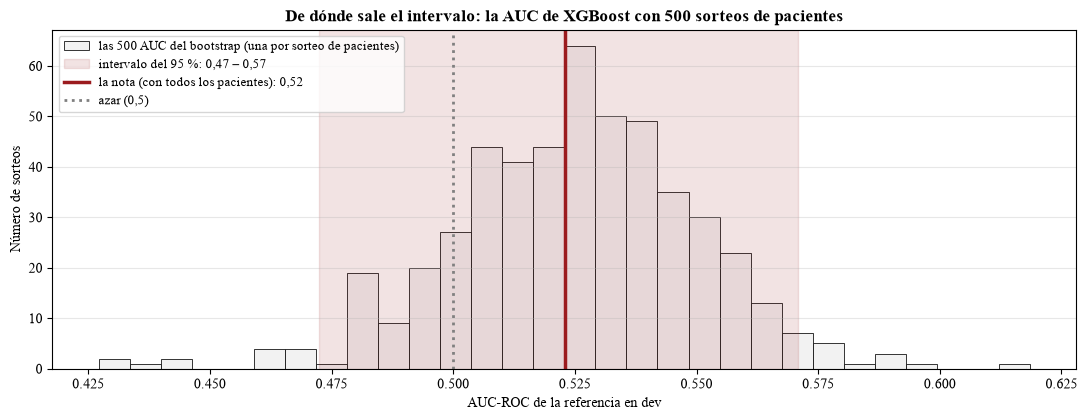

🔴 **El intervalo [0,47 – 0,57] contiene el 0,5:** con otros pacientes parecidos, la nota podría ser la del azar. **No se puede afirmar que la línea base sea mejor que tirar una moneda.**

In [15]:
# 1) Las 500 AUC del bootstrap de la referencia (mismos sorteos que su intervalo: misma semilla)
muestras_ref = muestras_auroc_bootstrap(y[validar], p_ref[validar], pacientes[validar],
                                        n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)

# 2) Dibujar el histograma con la nota, el intervalo y el azar
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(11, 4.3))
    ax.hist(muestras_ref, bins=30, color=COLORES_ESQUEMA['fondo_gris'], edgecolor=COLORES_ESQUEMA['negro'], lw=0.6,
            label=f'las {numero_legible(len(muestras_ref))} AUC del bootstrap (una por sorteo de pacientes)')
    ax.axvspan(inf_ref, sup_ref, color=COLORES_ESQUEMA['rojo'], alpha=0.12,
               label=f'intervalo del 95 %: {decimal(inf_ref)} – {decimal(sup_ref)}')
    ax.axvline(auc_ref, color=COLORES_ESQUEMA['rojo'], lw=2.5, label=f'la nota (con todos los pacientes): {decimal(auc_ref)}')
    ax.axvline(0.5, color='gray', ls=':', lw=2, label='azar (0,5)')

    # 3) Rotular y guardar
    ax.set_xlabel('AUC-ROC de la referencia en dev')
    ax.set_ylabel('Número de sorteos')
    ax.set_title(f'De dónde sale el intervalo: la AUC de {modelo_ref} con {numero_legible(len(muestras_ref))} sorteos de pacientes',
                 fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9, frameon=True)
    ax.grid(axis='y', alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'bootstrap_auc_dev.png', dpi=150, bbox_inches='tight')
    plt.show()

# 4) La lectura, escrita sola
if inf_ref <= 0.5:
    display(Markdown(f'🔴 **El intervalo [{decimal(inf_ref)} – {decimal(sup_ref)}] contiene el 0,5:** con otros pacientes parecidos, '
                     'la nota podría ser la del azar. **No se puede afirmar que la línea base sea mejor que tirar una moneda.**'))
else:
    display(Markdown(f'✅ **El intervalo [{decimal(inf_ref)} – {decimal(sup_ref)}] queda entero por encima de 0,5:** incluso con '
                     'otros pacientes parecidos, el modelo seguiría siendo mejor que el azar.'))

👀 **Cómo leer la figura.** Cada barra cuenta cuántos de los 500 sorteos de pacientes dieron esa AUC. La franja roja es el intervalo del 95 % (donde caen 475 de los 500), la raya roja es la nota con todos los pacientes y la raya de puntos, el azar. Si la raya de puntos cae **dentro** de la franja roja, no se puede descartar el azar.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejores, puntuaciones, nota</code> · las mejores pruebas, sus puntuaciones y su nota <i style="color:#4d4d4d">(§4 y §5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">clave_ref, modelo_ref, variante_ref</code> · cuál es la referencia <i style="color:#4d4d4d">(§5)</i></li></ul></div>

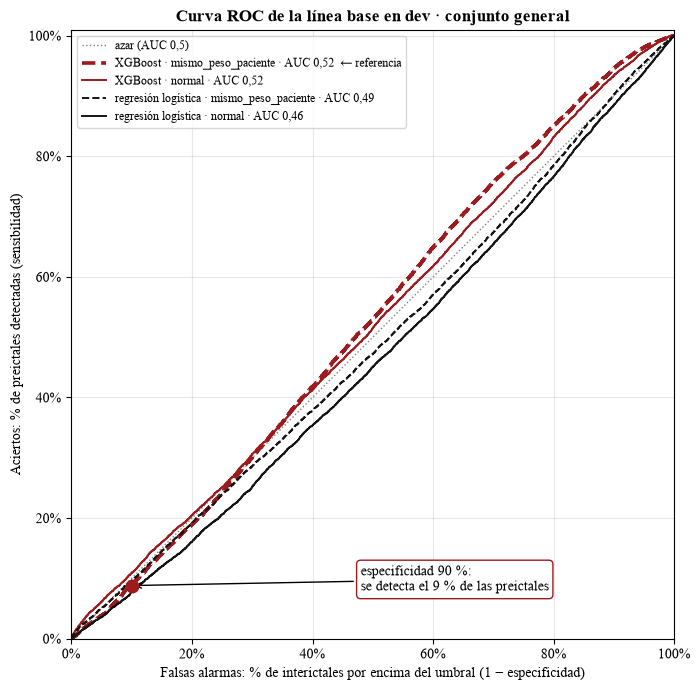

In [16]:
# 1) Estilo: un color por modelo y un tipo de línea por variante
ESTILO_MODELO = {'logistica': COLORES_ESQUEMA['negro'], 'xgboost': COLORES_ESQUEMA['rojo']}
ESTILO_VARIANTE = {'normal': '-', 'mismo_peso_paciente': '--'}
sens_ref = nota.loc[(modelo_ref, variante_ref), COLUMNA_SENSIBILIDAD]

with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(7.5, 7))

    # 2) Dibujar: el azar y una curva por modelo y variante (la referencia, más gruesa)
    ax.plot([0, 1], [0, 1], color='gray', lw=1, ls=':', label='azar (AUC 0,5)')
    for (nombre, variante), clave in mejores.items():
        fpr, tpr, _ = roc_curve(y[validar], puntuaciones[clave][validar])
        auc = nota.loc[(NOMBRES_MODELO[nombre], variante), 'AUC-ROC']
        es_ref = clave == clave_ref
        ax.plot(fpr, tpr, color=ESTILO_MODELO[nombre], ls=ESTILO_VARIANTE[variante], lw=2.6 if es_ref else 1.4,
                label=f'{NOMBRES_MODELO[nombre]} · {variante} · AUC {decimal(auc)}' + ('  ← referencia' if es_ref else ''))

    # 3) El punto de especificidad fija, con su nota abajo a la derecha (zona vacía)
    ax.plot(1 - ESPECIFICIDAD, sens_ref, 'o', color=COLORES_ESQUEMA['rojo'], ms=9, zorder=5)
    ax.annotate(f'especificidad {numero_legible(100 * ESPECIFICIDAD)} %:\n'
                f'se detecta el {numero_legible(round(100 * sens_ref))} % de las preictales',
                (1 - ESPECIFICIDAD, sens_ref), xytext=(0.48, 0.08), fontsize=10,
                bbox={'boxstyle': 'round,pad=0.3', 'fc': 'white', 'ec': COLORES_ESQUEMA['rojo']},
                arrowprops={'arrowstyle': '->', 'color': 'black'})

    # 4) Rotular (leyenda arriba a la izquierda, que está vacía) y guardar
    ax.set_xlabel('Falsas alarmas: % de interictales por encima del umbral (1 − especificidad)')
    ax.set_ylabel('Aciertos: % de preictales detectadas (sensibilidad)')
    ax.set_title(f'Curva ROC de la línea base en dev · conjunto {CONJUNTO}', fontsize=12, fontweight='bold')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect('equal')
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.3)
    ax.legend(loc='upper left', fontsize=8.5, frameon=True)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_roc_dev.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Cada curva es un modelo y una variante (negro = regresión logística, rojo = XGBoost; continua = normal, discontinua = mismo peso por paciente; la gruesa es la referencia). Al bajar el umbral se detectan más ⏳ (la curva sube) pero también saltan más falsas alarmas (avanza a la derecha). La diagonal de puntos es el azar. Cuanto más se pega la curva a la **esquina de arriba a la izquierda**, mejor; la AUC es el área que queda debajo. El punto rojo marca la sensibilidad con especificidad del 90 % de la referencia.

✅ **Qué deberías ver:** curvas por encima de la diagonal y bastante juntas entre sí (los dos modelos ven los mismos 110 números).

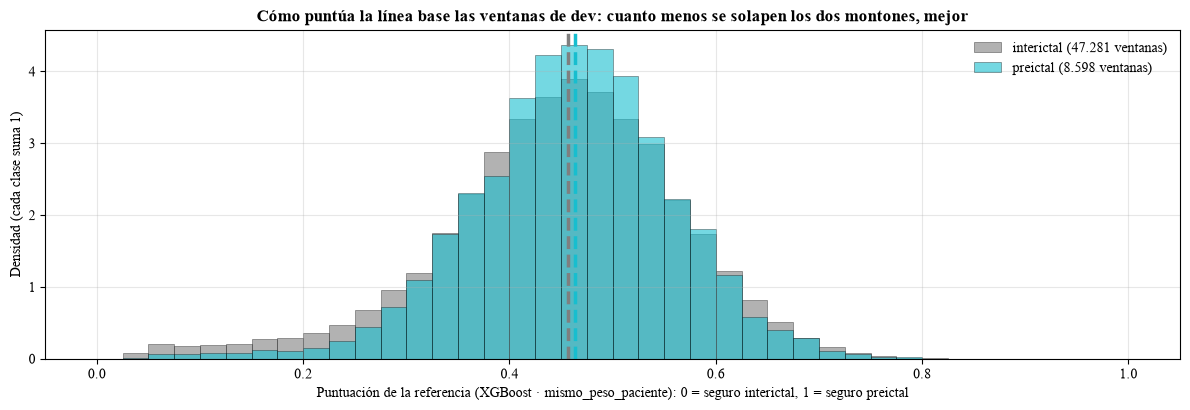

In [17]:
# Figura: cómo puntúa la referencia las ventanas ⏳ y 💤 de dev
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(12, 4.2))
    bins = np.linspace(0, 1, 41)

    # 1) Un histograma por clase, con su mediana
    for clase, etiqueta in [('interictal', 0), ('preictal', 1)]:
        datos = p_ref[validar & (y == etiqueta)]
        ax.hist(datos, bins=bins, density=True, alpha=0.6, color=COLORES_PERIODO[clase],
                edgecolor='black', lw=0.4, label=f'{clase} ({numero_legible(len(datos))} ventanas)')
        ax.axvline(np.median(datos), color=COLORES_PERIODO[clase], lw=2.5, ls='--')

    # 2) Rotular y guardar
    ax.set_xlabel(f'Puntuación de la referencia ({modelo_ref} · {variante_ref}): 0 = seguro interictal, 1 = seguro preictal')
    ax.set_ylabel('Densidad (cada clase suma 1)')
    ax.set_title('Cómo puntúa la línea base las ventanas de dev: cuanto menos se solapen los dos montones, mejor',
                 fontsize=12, fontweight='bold')
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'puntuaciones_dev.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Dos montones de ventanas de 🟡 dev según la puntuación que les da la referencia: 💤 interictales (gris) y ⏳ preictales (azul claro). Las líneas discontinuas son sus medianas. Cada montón está escalado para sumar 1, así que se comparan aunque haya muchas más 💤.

✅ **Qué deberías ver:** el montón ⏳ algo desplazado a la derecha, pero con mucho solape. Ese solape es lo que la red de F03.04 tiene que reducir.

## 6. Por paciente: ¿reconoce el momento dentro de cada persona?

> 🔑 **Idea clave de este notebook: la AUC por paciente.** Sirve para tres cosas:
> 1. **Es la nota que importa en la vida real.** Una app vigila a **una** persona: lo útil es que, dentro de esa persona, el modelo puntúe más alto los minutos antes de su crisis que sus ratos tranquilos.
> 2. **Destapa trampas.** Si la AUC global es buena y la AUC por paciente mala, el modelo reconoce **pacientes** ("este tiene muchas crisis: nota alta a todo") en vez de reconocer **el momento** antes de la crisis. Es el mismo tipo de atajo que buscó la auditoría de F02.05.
> 3. **Pasó a ser el criterio de decisión de la fase.** En F03.05 la escalera de mejoras se decide por la **AUC dentro del paciente**, y la normalización por paciente de F03.03 (comparar a cada paciente consigo mismo) ataca justo este problema. Aquí, en F03.02, es donde se ve por primera vez por qué hace falta.
>
> En la memoria servirá además para enseñar lo **desigual** que es la predicción entre pacientes y para buscar en cuáles falla.

**Qué es y qué no es.** Hay **un solo modelo**, general, entrenado con los pacientes de 🔵 train. Puntúa las ventanas de 🟡 dev (pacientes que no ha visto nunca) y, **con esas mismas puntuaciones**, se ponen dos notas:
- **Global (§5):** se mezclan las ventanas de todos los pacientes de dev y se calcula una AUC.
- **Por paciente (aquí):** se cogen solo las ventanas del paciente X (sus ⏳ y sus 💤) y se calcula su AUC. Luego el paciente Y, y así con todos.

Es como un examen: el mismo examen corregido da la **nota media de la clase** (global) y la **nota de cada alumno** (por paciente). **No hace falta ningún dato anterior del paciente**: las etiquetas ⏳/💤 de dev solo se usan para corregir, no para entrenar. (Ajustar el modelo con crisis ya grabadas de una persona sería un **modelo personalizado**: es otra estrategia, y aquí no se usa.)

**Por qué se calcula por paciente: el modelo tramposo.**

![El modelo tramposo: AUC global frente a AUC por paciente](img/modelo_tramposo.png)

👀 **Qué enseña.** Dos pacientes de dev. **A** tiene muchas crisis (casi todas sus ventanas son ⏳) y el modelo le pone **≈0,8 a todo**. **B** casi no tiene crisis (casi todo 💤) y el modelo le pone **≈0,2 a todo**.
- **① Mezclando**, las ⏳ (casi todas de A, a 0,8) quedan por encima de las 💤 (casi todas de B, a 0,2): la **AUC global sale alta**.
- **② Dentro de cada paciente**, todo tiene la misma puntuación: el modelo no distingue sus ⏳ de sus 💤, así que **AUC 0,5** en los dos.

El modelo no ha aprendido **cuándo** se acerca una crisis, solo **quién** tiene muchas. En una app tendría que avisar **cuando la puntuación de esa persona sube** antes de una crisis; un modelo que le pone a cada persona siempre la misma nota no avisaría nunca en el momento justo, aunque su AUC global fuera espectacular.

> ⚠️ **Cuidado con los pacientes de pocas ⏳.** 58 ventanas preictales son, más o menos, **una sola crisis**: la AUC de ese paciente puede salir alta o baja por suerte. Por eso se mira el **conjunto** de pacientes (la mediana, cuántos superan el azar) y no se saca ninguna conclusión de uno solo.

Solo tienen AUC propia los pacientes de dev con ventanas de las **dos** clases (con alguna crisis y algún tramo tranquilo).

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_ref, nombre_ref, variante_ref</code> · la puntuación y la identidad de la referencia <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejores, puntuaciones</code> · para calcular también la otra variante de peso <i style="color:#4d4d4d">(§4 y §5)</i></li></ul></div>

In [18]:
# 1) La otra variante de peso del mismo modelo (para comparar)
otra_variante = [v for v in VARIANTES if v != variante_ref][0]
clave_otra = mejores[(nombre_ref, otra_variante)]

# 2) AUC de cada paciente con la referencia y con la otra variante, de peor a mejor
por_paciente = (auroc_por_paciente(y[validar], p_ref[validar], pacientes[validar])
                .join(auroc_por_paciente(y[validar], puntuaciones[clave_otra][validar], pacientes[validar])[['auroc']]
                      .rename(columns={'auroc': f'auroc ({otra_variante})'}))
                .sort_values('auroc'))

# 3) Resumen en una fila
resumen_paciente = pd.DataFrame({
    'pacientes con AUC propia': [len(por_paciente)],
    'mediana': [por_paciente.auroc.median()],
    '% de pacientes por encima de 0,5': [100 * (por_paciente.auroc > 0.5).mean()],
    'peor': [por_paciente.auroc.min()],
    'mejor': [por_paciente.auroc.max()],
    'AUC global (§5)': [auc_ref]}, index=[f'{modelo_ref} · {variante_ref}'])
resumen_paciente.index.name = 'referencia'
display(con_separadores(resumen_paciente, decimales=2))

,pacientes con AUC propia,mediana,"% de pacientes por encima de 0,5",peor,mejor,AUC global (§5)
referencia,,,,,,
XGBoost · mismo_peso_paciente,30,"0,54","56,67","0,26","0,84","0,52"


👀 **Cómo leer la tabla.** Cuántos pacientes de dev tienen AUC propia, la **mediana** (la nota del paciente típico), qué parte supera el azar, el peor y el mejor caso, y al lado la AUC global de §5 para compararlas.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_paciente</code> · tabla con una fila por paciente de dev: su AUC con la referencia, sus ventanas ⏳ y 💤, y su AUC con la otra variante <i style="color:#4d4d4d">(celda anterior)</i></li></ul></div>

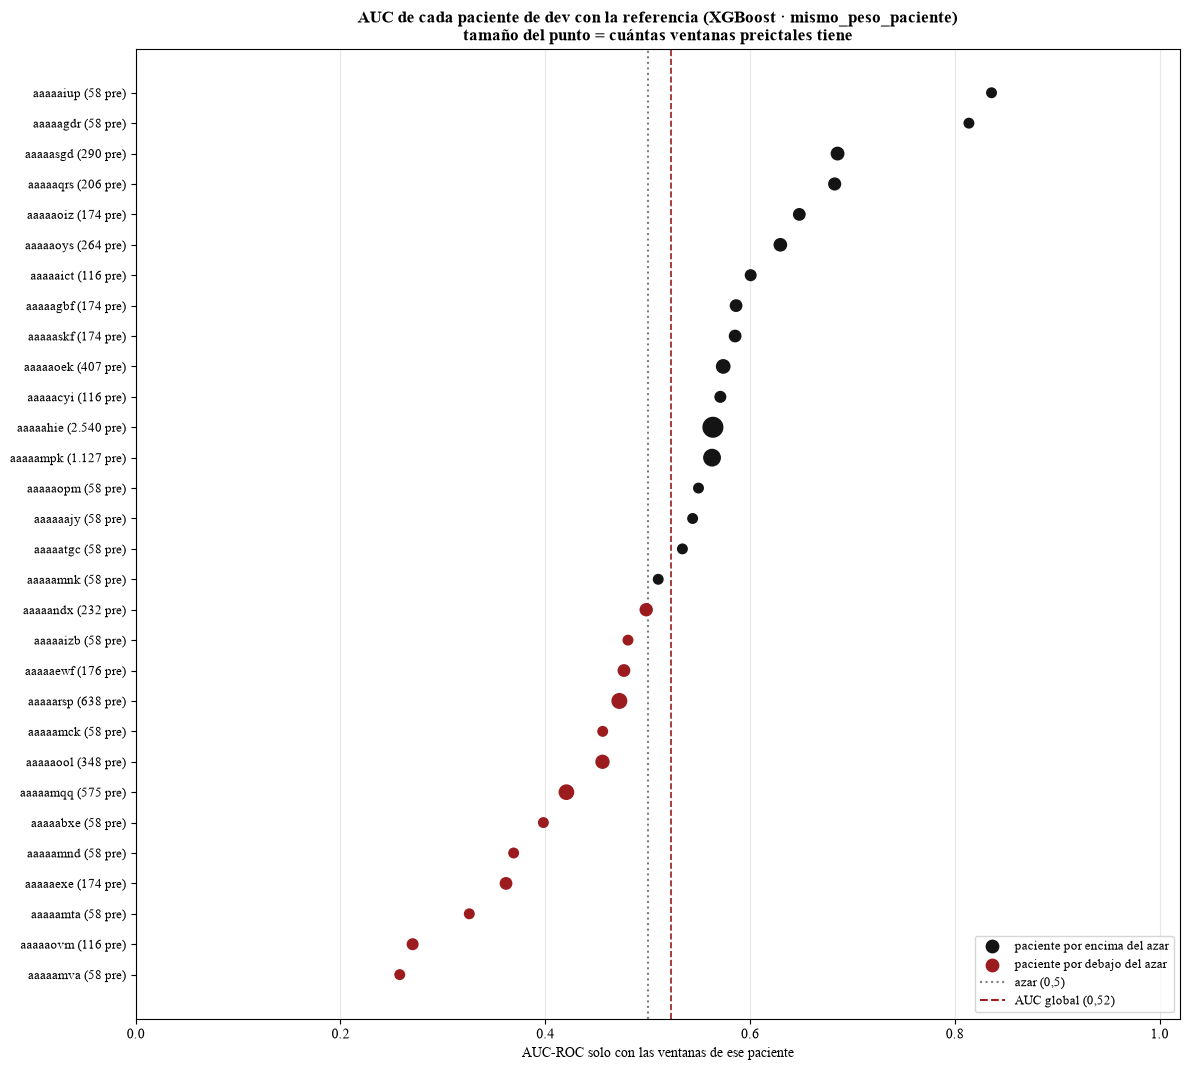

**17 de 30 pacientes** quedan por encima del azar y **13** por debajo. Es como **tirar una moneda paciente a paciente**: el modelo no ordena de forma fiable dentro de cada persona. 

**¿Es estable?** Con la otra forma de pesar (normal), la AUC de un mismo paciente cambia de media 0,07 y como mucho 0,20 (paciente `aaaaatgc`: 0,53 con la referencia y 0,34 con la otra). Cuando un detalle tan pequeño cambia tanto la nota de un paciente, **el modelo no ha aprendido nada estable**.

In [19]:
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(12, max(4.5, 0.3 * len(por_paciente) + 1.8)))

    # 1) Preparar: una fila por paciente; el tamaño del punto = cuántas ⏳ tiene
    filas_y = np.arange(len(por_paciente))
    tamano = 20 + 180 * np.sqrt(por_paciente['⏳ preictal'] / por_paciente['⏳ preictal'].max())
    colores = [COLORES_ESQUEMA['rojo'] if a < 0.5 else COLORES_ESQUEMA['negro'] for a in por_paciente.auroc]

    # 2) Dibujar: la AUC de cada paciente, el azar y la AUC global
    ax.scatter(por_paciente.auroc, filas_y, s=tamano, color=colores, zorder=3)
    ax.axvline(0.5, color='gray', ls=':', lw=1.5)
    ax.axvline(auc_ref, color=COLORES_ESQUEMA['rojo'], ls='--', lw=1.2)
    ax.scatter([], [], s=80, color=COLORES_ESQUEMA['negro'], label='paciente por encima del azar')
    ax.scatter([], [], s=80, color=COLORES_ESQUEMA['rojo'], label='paciente por debajo del azar')
    ax.plot([], [], color='gray', ls=':', label='azar (0,5)')
    ax.plot([], [], color=COLORES_ESQUEMA['rojo'], ls='--', label=f'AUC global ({decimal(auc_ref)})')

    # 3) Rotular (leyenda dentro, abajo a la derecha, que está vacía) y guardar
    ax.set_yticks(filas_y, [f'{p} ({numero_legible(int(n))} pre)' for p, n in zip(por_paciente.index, por_paciente['⏳ preictal'])],
                  fontsize=9)
    ax.set_xlabel('AUC-ROC solo con las ventanas de ese paciente')
    ax.set_xlim(0, 1.02)
    ax.set_title(f'AUC de cada paciente de dev con la referencia ({modelo_ref} · {variante_ref})\n'
                 'tamaño del punto = cuántas ventanas preictales tiene', fontsize=12, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    ax.legend(loc='lower right', fontsize=9, frameon=True)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'auc_por_paciente_dev.png', dpi=150, bbox_inches='tight')
    plt.show()

# 4) Qué dice, escrito solo a partir de los datos
n_encima, n_total = int((por_paciente.auroc > 0.5).sum()), len(por_paciente)
cambio_variante = (por_paciente.auroc - por_paciente[f'auroc ({otra_variante})']).abs()
paciente_cambia = cambio_variante.idxmax()
fila_cambia = por_paciente.loc[paciente_cambia]

lectura = f'**{n_encima} de {n_total} pacientes** quedan por encima del azar y **{n_total - n_encima}** por debajo. '
if 0.35 <= n_encima / n_total <= 0.65:
    lectura += 'Es como **tirar una moneda paciente a paciente**: el modelo no ordena de forma fiable dentro de cada persona. '
elif n_encima / n_total > 0.65:
    lectura += 'La mayoría supera el azar: dentro de cada persona el modelo ordena algo, aunque de forma muy desigual. '
else:
    lectura += 'La mayoría queda por debajo del azar: dentro de cada persona el modelo ordena al revés más veces que bien. '
lectura += (f'\n\n**¿Es estable?** Con la otra forma de pesar ({otra_variante}), la AUC de un mismo paciente cambia de media '
            f'{decimal(cambio_variante.mean())} y como mucho {decimal(cambio_variante.max())} (paciente `{paciente_cambia}`: '
            f'{decimal(fila_cambia.auroc)} con la referencia y {decimal(fila_cambia[f"auroc ({otra_variante})"])} con la otra). ')
lectura += ('Cuando un detalle tan pequeño cambia tanto la nota de un paciente, **el modelo no ha aprendido nada estable**.'
            if cambio_variante.max() > 0.15 else 'Las dos variantes dan notas parecidas por paciente: lo que aprende es estable.')
display(Markdown(lectura))

👀 **Cómo leer la figura.** Cada fila es un paciente de 🟡 dev, ordenados de peor a mejor; entre paréntesis, cuántas ventanas ⏳ tiene. El punto es su AUC con la referencia: **negro** si supera el azar (0,5) y **rojo** si queda por debajo. El tamaño del punto dice cuántas ⏳ tiene ese paciente (cuánto pesa en la nota global). La raya de puntos es el azar y la discontinua roja, la AUC global.

✅ **Qué deberías ver:** si el modelo funcionara, casi todos los puntos estarían a la derecha de 0,5. El texto de debajo de la figura dice cuántos lo están y si la nota de cada paciente es estable al cambiar la forma de pesar. Si la mediana por paciente queda muy por debajo de la AUC global, parte de la nota global viene de distinguir pacientes (el modelo tramposo). Las conclusiones (§12) lo dicen solas.

## 7. Por grupo de crisis: ¿cuál se predice mejor?

> 🎯 **Qué hacemos:** repetir la AUC de la referencia separando las ⏳ por **grupo de inicio** de su crisis (♦️ focal, 🔷 generalizada, 🔹 ausencia), siempre frente a **todas** las 💤 de dev.
>
> 🤔 **Por qué:** el modelo general mezcla los tres grupos. Ver cuál predice mejor y cuál peor dice si merece la pena el modelo por grupo que está previsto probar después. Ojo: las ausencias tienen sus propios umbrales (lead-in de 60 s y SPH de 10 s) y aquí se miden con el modelo general.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">filas, y, validar, pacientes</code> · quién es cada ventana, su etiqueta, si se mide y su paciente <i style="color:#4d4d4d">(§3 y §4)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">p_ref</code> · la puntuación de la referencia <i style="color:#4d4d4d">(§5)</i></li></ul></div>

In [20]:
filas_grupo = {}
interictal_val = validar & (y == 0)
grupos_presentes = set(filas.grupo[validar & (y == 1)].dropna())

for grupo in [g for g in ['focal', 'generalizada', 'ausencia'] if g in grupos_presentes]:
    # 1) Las ⏳ de este grupo frente a TODAS las 💤 de dev
    con_grupo = validar & (y == 1) & (filas.grupo.to_numpy() == grupo)
    if con_grupo.sum() == 0:
        continue
    mascara = interictal_val | con_grupo

    # 2) Su AUC con intervalo
    auc, inferior, superior = auroc_con_intervalo(y[mascara], p_ref[mascara], pacientes[mascara],
                                                  n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    filas_grupo[con_icono(grupo)] = {'pacientes con ⏳': len(set(pacientes[con_grupo])),
                                     'crisis': filas.crisis_id[con_grupo].nunique(),
                                     '⏳ preictal': int(con_grupo.sum()),
                                     'AUC-ROC': auc,
                                     'IC 95 % (por paciente)': f'{decimal(inferior)} – {decimal(superior)}'}

# 3) Tabla
por_grupo = pd.DataFrame(filas_grupo).T
por_grupo.index.name = 'grupo de inicio'
if len(por_grupo):
    por_grupo['AUC-ROC'] = por_grupo['AUC-ROC'].astype(float)
    display(con_separadores(por_grupo, decimales=3))
else:
    print('🟡 Las ventanas de validación no traen el grupo de inicio de su crisis: no se puede separar por grupo.')

,pacientes con ⏳,crisis,⏳ preictal,AUC-ROC,IC 95 % (por paciente)
grupo de inicio,,,,,
♦️ focal,20,108,6.017,"0,527","0,47 – 0,58"
🔷 generalizada,16,42,2.232,"0,507","0,42 – 0,60"
🔹 ausencia,3,6,349,"0,560","0,48 – 0,75"


👀 **Cómo leer la tabla.** Una fila por grupo: de cuántos pacientes y crisis salen sus ventanas ⏳ en dev, y la AUC de la referencia distinguiendo **esas** ⏳ de todas las 💤, con su intervalo.

✅ **Qué deberías ver:** diferencias entre grupos. **Cuidado** con los grupos de pocos pacientes (sobre todo 🔹 ausencia): su intervalo será ancho y la cifra, frágil. Para las ausencias, la cifra buena es la de la validación cruzada por paciente (conjunto `grupo_ausencia`), como está previsto.

## 8. Qué ha aprendido: qué bandas y canales usa

> 🎯 **Qué hacemos:** mirar dentro de los dos modelos para ver qué características usan para decidir.
>
> 🤔 **Por qué:** es la ventaja de una línea base clásica: se puede **explicar**. Además adelanta la Fase 5 (explicabilidad): si la red de F03.04 mirara bandas y canales parecidos, sería una buena señal; si mirara cosas sin sentido clínico, una alarma.

- **Regresión logística**: el **peso** de cada característica, **con signo** y sin unidades. Antes de entrenar, cada característica se pone en la misma escala (media 0 y desviación 1), así que los pesos se pueden comparar entre sí. **El signo dice la dirección**: positivo (rojo) = cuanta más energía en esa banda de ese canal, más ⏳ preictal; negativo (azul) = más 💤 interictal. **El tamaño dice la fuerza**: cerca de 0 (blanco), esa casilla casi no influye.
- **XGBoost**: la **parte de la ganancia total**, en %: cuánto le ha servido cada casilla a los árboles para separar ⏳ de 💤. Las 110 casillas suman el 100 %. **No tiene signo**: dice cuánto la usa, no hacia qué lado empuja. Si las usara todas por igual, cada una valdría 1/110 ≈ 0,9 % (la raya negra de su barra de color).

Se usan los mejores hiperparámetros de cada modelo (de la variante con mejor AUC), entrenados con **todas** las ventanas de entrenamiento.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">nota, mejores, hiperparametros</code> · la nota de cada combinación, las mejores pruebas y sus hiperparámetros <i style="color:#4d4d4d">(§4 y §5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X, y, pacientes, filas</code> · los datos de las ventanas <i style="color:#4d4d4d">(§3)</i></li></ul></div>

In [21]:
# Los dos modelos finales: mejores hiperparámetros y variante, entrenados con todas las ventanas de entrenamiento
entrena = filas.en_entrenamiento.to_numpy(dtype=bool)
finales, pesos = {}, {}

for nombre in MODELOS:
    variante = nota.loc[NOMBRES_MODELO[nombre], 'AUC-ROC'].idxmax()
    clave = mejores[(nombre, variante)]
    modelo = entrenar(nombre, hiperparametros[clave], X[entrena], y[entrena], pacientes[entrena], variante, SEMILLA)
    finales[nombre] = (modelo, clave)
    pesos[nombre] = pesos_explicativos(nombre, modelo).reshape(len(CANALES_TCP), len(BANDAS))   # canales × bandas

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">finales</code> · modelo → (modelo entrenado, su prueba) <i style="color:#4d4d4d">(celda anterior)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">pesos</code> · modelo → rejilla 22 × 5 con cuánto usa cada casilla (logística: peso con signo; XGBoost: parte de la ganancia, suma 1) <i style="color:#4d4d4d">(celda anterior)</i></li></ul></div>

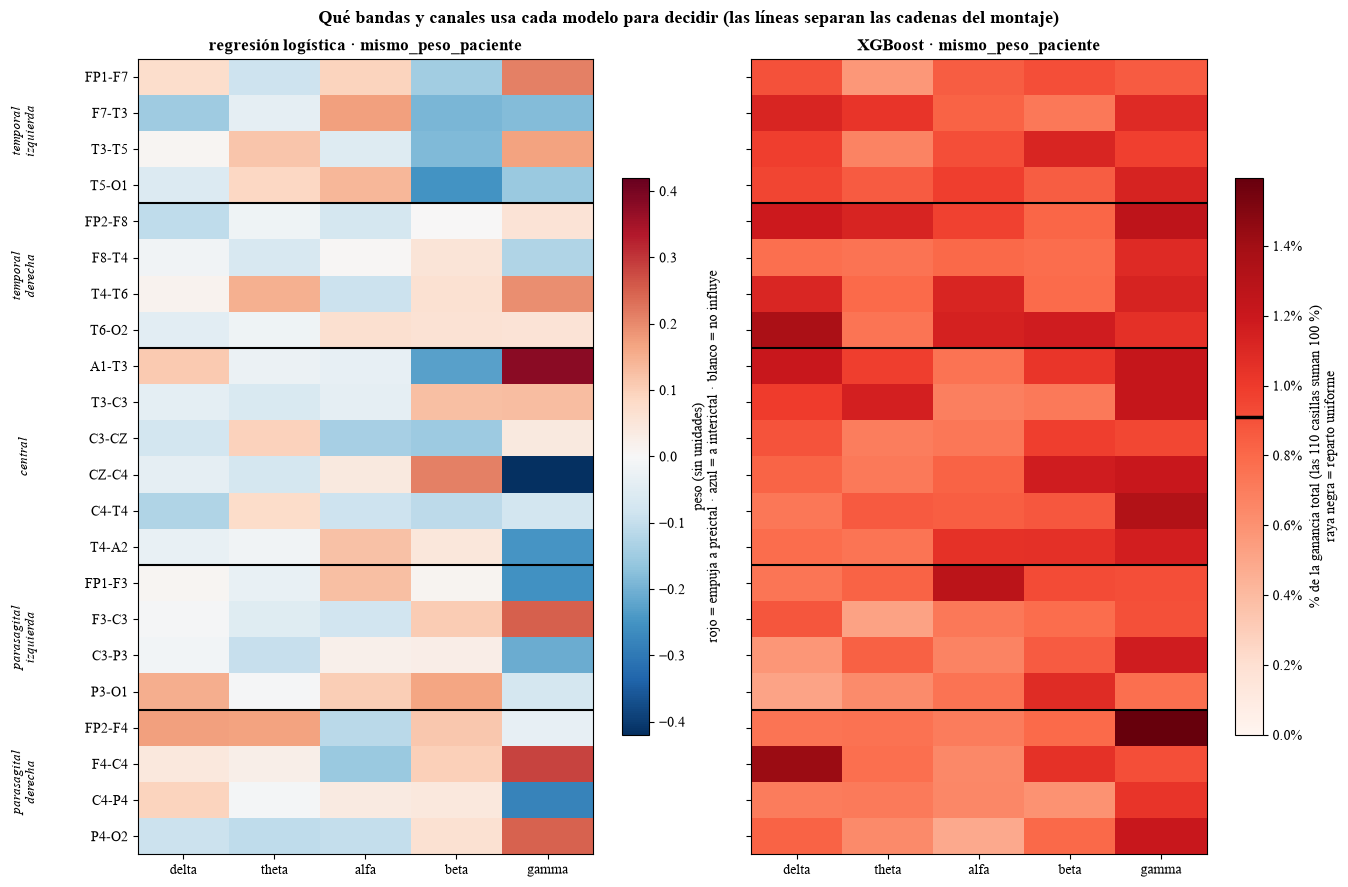

**Lo revelador:** si el modelo usara todas las casillas por igual, cada una valdría 1/110 ≈ **0,9 %**. Aquí casi todas están entre el 0,7 % y el 1,2 % (la que más, 1,6 %), así que **XGBoost reparte casi por igual y ninguna característica destaca**. Encaja con la nota casi de azar: **no ha encontrado ninguna pista clara**.

In [22]:
# 1) Preparar: dónde van las líneas entre cadenas del montaje, y la ganancia de XGBoost en %
limites_cadena = np.cumsum([len(p) for p in CADENAS_TCP.values()])[:-1] - 0.5
ganancia_pct = 100 * pesos['xgboost']
uniforme_pct = 100 / ganancia_pct.size                        # si las usara todas por igual (1/110 ≈ 0,9 %)
tope = np.abs(pesos['logistica']).max()

paneles = [('logistica', pesos['logistica'], 'RdBu_r', -tope, tope,
            'peso (sin unidades)\nrojo = empuja a preictal · azul = a interictal · blanco = no influye'),
           ('xgboost', ganancia_pct, 'Reds', 0, ganancia_pct.max(),
            '% de la ganancia total (las 110 casillas suman 100 %)\nraya negra = reparto uniforme')]

with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 9), sharey=True)

    # 2) Dibujar: un mapa por modelo, con sus líneas entre cadenas y su barra de color explicada
    for ax, (nombre, valores, mapa, vmin, vmax, rotulo) in zip(axes, paneles):
        imagen = ax.imshow(valores, cmap=mapa, vmin=vmin, vmax=vmax, aspect='auto')
        for limite in limites_cadena:
            ax.axhline(limite, color='black', lw=1.5)
        ax.set_xticks(range(len(BANDAS)), BANDAS)
        ax.set_title(f'{NOMBRES_MODELO[nombre]} · {finales[nombre][1][1]}', fontsize=12, fontweight='bold')
        barra = fig.colorbar(imagen, ax=ax, shrink=0.7)
        barra.set_label(rotulo, fontsize=10)
        if nombre == 'xgboost':
            barra.ax.axhline(uniforme_pct, color='black', lw=2.5)
            barra.ax.yaxis.set_major_formatter(PercentFormatter(decimals=1))

    # 3) Nombres de canales y de cadenas a la izquierda
    axes[0].set_yticks(range(len(CANALES_TCP)), CANALES_TCP)
    for limite, (cadena, pares) in zip([-0.5, *limites_cadena], CADENAS_TCP.items()):
        axes[0].text(-1.75, limite + len(pares) / 2, cadena.replace(' ', '\n'), fontsize=9, va='center', ha='center',
                     rotation=90, style='italic', clip_on=False)

    # 4) Rotular y guardar
    fig.suptitle('Qué bandas y canales usa cada modelo para decidir (las líneas separan las cadenas del montaje)',
                 fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'que_ha_aprendido.png', dpi=150, bbox_inches='tight')
    plt.show()

# 5) Lo revelador, escrito solo a partir de los datos: ¿XGBoost reparte por igual o hay casillas que destacan?
p10, p90 = np.percentile(ganancia_pct, [10, 90])
maximo = ganancia_pct.max()
if maximo < 2 * uniforme_pct:
    lectura_ganancia = (f'**Lo revelador:** si el modelo usara todas las casillas por igual, cada una valdría 1/{ganancia_pct.size} ≈ '
                        f'**{decimal(uniforme_pct, 1)} %**. Aquí casi todas están entre el {decimal(p10, 1)} % y el {decimal(p90, 1)} % '
                        f'(la que más, {decimal(maximo, 1)} %), así que **XGBoost reparte casi por igual y ninguna característica destaca**.')
    if auc_ref < 0.6:
        lectura_ganancia += ' Encaja con la nota casi de azar: **no ha encontrado ninguna pista clara**.'
else:
    lectura_ganancia = (f'**Lo revelador:** con un reparto uniforme cada casilla valdría ≈ {decimal(uniforme_pct, 1)} %, pero la que más '
                        f'usa XGBoost llega al **{decimal(maximo, 1)} %** (más del doble): hay características que destacan.')
display(Markdown(lectura_ganancia))

In [23]:
# 1) Tabla de importancia: una fila por característica, con lo que dice cada modelo
importancia = pd.DataFrame({'característica': NOMBRES,
                            'peso logística': pesos['logistica'].ravel(),
                            'ganancia XGBoost': pesos['xgboost'].ravel()})
importancia['dirección (logística)'] = np.where(importancia['peso logística'] > 0, '⏳ más preictal', '💤 más interictal')

# 2) Las 10 que más usan los dos a la vez (suma de su puesto en cada modelo)
puesto = (importancia['ganancia XGBoost'].rank(ascending=False)
          + importancia['peso logística'].abs().rank(ascending=False))
top = (importancia.assign(orden=puesto).sort_values('orden').head(10)
       .drop(columns='orden').set_index('característica'))
display(Markdown('**Las 10 características que más usan los dos modelos a la vez** (suma de su puesto en cada modelo)'))
display(con_separadores(top, decimales=3))

# 3) ¿Miran sobre todo bandas rápidas? beta y gamma también recogen actividad muscular
rapidas = sum(c.endswith('· beta') or c.endswith('· gamma') for c in top.index)
if rapidas >= 6:
    display(Markdown(f'🟡 **{rapidas} de las 10** son de **beta o gamma**. Son las bandas más contaminadas por el **músculo** (tensión, mandíbula, '
                     'movimientos). Con una nota cercana al azar, puede que el modelo se agarre a ese "ruido" más que a cambios cerebrales. '
                     'No es un error, pero hay que tenerlo en cuenta al interpretarlo y en la Fase 5.'))
else:
    print(f'Bandas rápidas (beta/gamma) entre las 10 más usadas: {rapidas} de 10.')

**Las 10 características que más usan los dos modelos a la vez** (suma de su puesto en cada modelo)

,peso logística,ganancia XGBoost,dirección (logística)
característica,,,
A1-T3 · gamma,"0,380","0,012",⏳ más preictal
CZ-C4 · gamma,"-0,420","0,012",💤 más interictal
P4-O2 · gamma,"0,248","0,012",⏳ más preictal
CZ-C4 · beta,"0,211","0,012",⏳ más preictal
T4-A2 · gamma,"-0,248","0,012",💤 más interictal
C3-P3 · gamma,"-0,207","0,012",💤 más interictal
T4-T6 · gamma,"0,195","0,011",⏳ más preictal
C4-P4 · gamma,"-0,280","0,010",💤 más interictal
T3-T5 · beta,"-0,184","0,011",💤 más interictal


🟡 **9 de las 10** son de **beta o gamma**. Son las bandas más contaminadas por el **músculo** (tensión, mandíbula, movimientos). Con una nota cercana al azar, puede que el modelo se agarre a ese "ruido" más que a cambios cerebrales. No es un error, pero hay que tenerlo en cuenta al interpretarlo y en la Fase 5.

👀 **Cómo leer la figura y la tabla.** Cada mapa tiene una fila por canal (agrupados por cadena del montaje, separadas con líneas) y una columna por banda.

- **Izquierda (logística):** la barra de color va de un peso negativo a uno positivo, **sin unidades**. Rojo = esa casilla empuja hacia ⏳ preictal; azul = hacia 💤 interictal; blanco = casi no influye. Cuanto más intenso, más fuerza.
- **Derecha (XGBoost):** la barra está en **% de la ganancia total**; las 110 casillas suman 100 %. Más oscuro = la usa más. La **raya negra** de la barra es el reparto uniforme (≈ 0,9 %): las casillas por encima de esa raya las usa más de lo que tocaría por igual.
- **La tabla** junta las 10 características que más usan **los dos**, con la dirección según la logística.

✅ **Qué deberías ver:** algunas bandas o regiones que destacan en los dos modelos. Que coincidan da confianza. Que el peso se reparta por muchos canales a la vez es esperable en un modelo **general** (mezcla crisis focales de distintos sitios y generalizadas). El párrafo de debajo de la figura dice si XGBoost encuentra alguna casilla que destaque o lo reparte todo casi por igual.

> 💪 **Un detalle de las bandas rápidas.** beta (13-30 Hz) y gamma (30-45 Hz) se mezclan con la actividad de los **músculos** de la cabeza (apretar la mandíbula, tensión, movimientos). Si el modelo se apoya sobre todo en ellas, puede estar mirando el músculo y no el cerebro. La celda de arriba avisa si pasa.

> ⚠️ **Esto no es todavía explicabilidad clínica.** Los pesos de la logística pueden repartirse entre características muy parecidas (canales vecinos) y la ganancia de XGBoost no tiene signo. Sirve para ver **por dónde** mira el modelo; la explicación seria llega en la Fase 5.

## 9. Comprobación: con los mismos números, ¿se detecta la crisis?

> 🎯 **Qué hacemos:** usar **las mismas** 110 características y **los mismos** modelos para una tarea que se sabe que funciona: distinguir ventanas **⚡ ictales** (durante la crisis) de **💤 interictales**. Es **detección**, no predicción.
>
> 🤔 **Por qué:** si la línea base de predicción sale cerca del azar (§5), hay dos explicaciones: (1) predecir con 4 s sueltos y en pacientes nuevos es así de difícil, o (2) algo falla en la cadena de la Fase 2 (etiquetas, ventanas, filtrado, paquetes). Esta prueba las separa:
> - Si la **detección sale alta** (en TUSZ se publican AUC de 0,8-0,9; Tang 2021, Wu 2025), la cadena está bien y lo difícil es **predecir**.
> - Si la detección **también sale cerca de 0,5**, hay un fallo que buscar **antes** de construir la red.

![Detectar no es predecir](img/detectar_frente_a_predecir.png)

👀 **Qué enseña.** Una grabación alrededor de una crisis. **Predecir** es reconocer el tramo gris (el minuto de antes): la onda casi no cambia y el cambio es distinto en cada persona. **Detectar** es reconocer el tramo rojo (la crisis): la onda cambia muchísimo. Si con los mismos números se **detecta** bien pero no se **predice**, los datos están bien y el problema es la tarea.

**Qué ventanas se usan** (todo de 🔵 train y 🟡 dev; 🟢 eval sigue sin tocarse):
- ⚡ **ictales**: las de `conjuntos/clasificacion.csv` de F02.04 (las que usará la Fase 4). Se empaquetan como en F03.01, en `paquetes/ictal/`, y la Fase 4 podrá reutilizarlas.
- 💤 **interictales**: las mismas de este notebook (las de *entrenamiento* para entrenar y las de *validacion* para medir).
- Los **modelos**: los mejores hiperparámetros de §4 para cada modelo, en la variante normal. No se ajusta nada para esta prueba.

> 💡 La primera vez empaqueta las ventanas ictales (unos minutos, ~3 GB) y calcula sus características. Las siguientes veces lo reutiliza.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">SPLITS</code> · las particiones que se usan (🔵 train y 🟡 dev) <i style="color:#4d4d4d">(§2)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">NOMBRES, MUESTRAS, FS</code> · los nombres de las 110 características, muestras por ventana y por segundo <i style="color:#4d4d4d">(§2)</i></li></ul></div>

In [24]:
# 1) Qué ventanas ⚡ ictales hay: las de clasificacion.csv de F02.04, solo de 🔵 train y 🟡 dev
CONJUNTO_ICTAL = 'ictal'          # nombre del paquete de ventanas ⚡ ictales (compartido con la Fase 4)
ruta_clasificacion = RUTA_OUTPUTS_FASE_02 / '04_particiones_y_balanceo' / 'conjuntos' / 'clasificacion.csv'
assert ruta_clasificacion.exists(), f'No encuentro {ruta_clasificacion}. Ejecuta antes F02.04 (fase_02/04_particiones_y_balanceo.ipynb).'

ictales = pd.read_csv(ruta_clasificacion)
ictales = ictales[(ictales.clase == 'ictal') & ictales.split.isin(SPLITS)]

partes_ictal, filas_ictal_calculo = [], {}
for split in SPLITS:
    inicio = time.time()

    # 2) Empaquetarlas (solo la primera vez) y abrir el paquete
    indice = ictales[ictales.split == split].sort_values(['patient', 'file', 'ruta', 'muestra_inicio']).reset_index(drop=True)
    if not paquete_al_dia(CONJUNTO_ICTAL, split, indice, len(CANALES_TCP), MUESTRAS):
        crear_paquete(CONJUNTO_ICTAL, split, indice, len(CANALES_TCP), MUESTRAS,
                      progreso=lambda it, total: tqdm(it, total=total, desc=f'{split}: tramos ictales leídos'))
    matriz, indice = cargar_paquete(CONJUNTO_ICTAL, split)

    # 3) Sus 110 números (solo la primera vez)
    estado = 'ya estaba al día'
    if not caracteristicas_al_dia(CONJUNTO_ICTAL, split, indice.id_ventana, len(NOMBRES)):
        estado = 'calculada'
        X_nuevas = caracteristicas_por_trozos(matriz, FS, progreso=lambda it, total: tqdm(it, total=total, desc=f'{split}: características'))
        guardar_caracteristicas(CONJUNTO_ICTAL, split, indice.id_ventana.to_numpy(), X_nuevas)
    X_ictal, ids = cargar_caracteristicas(CONJUNTO_ICTAL, split)
    assert (ids == indice.id_ventana.to_numpy()).all()

    partes_ictal.append((indice, X_ictal))
    filas_ictal_calculo[split] = {'características': estado, 'ventanas ⚡ ictales': len(indice), 'pacientes': indice.patient.nunique(),
                                  'crisis': indice.crisis_id.nunique(), 'segundos': time.time() - inicio}

# 4) Tabla
tabla_ictal = pd.DataFrame(filas_ictal_calculo).T
tabla_ictal.index.name = 'split'
display(con_separadores(tabla_con_iconos(tabla_ictal), decimales=1))

,características,ventanas ⚡ ictales,pacientes,crisis,segundos
split,,,,,
🔵 train,ya estaba al día,56.320,169,1.767,"0,4"
🟡 dev,ya estaba al día,12.535,37,489,"0,1"


👀 **Cómo leer la tabla.** Una fila por partición: si las características de las ventanas ⚡ ictales se han calculado ahora o ya estaban, cuántas ventanas, de cuántos pacientes y crisis salen, y cuánto ha tardado (la primera vez incluye empaquetarlas).

✅ **Qué deberías ver:** miles de ventanas ⚡ en 🔵 train y en 🟡 dev, de decenas de pacientes.

Se juntan las ⚡ ictales con las 💤 interictales de este notebook: las de 🔵 train para entrenar y las de 🟡 dev para medir.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">partes_ictal</code> · lista de (índice, 110 números) de las ventanas ⚡ de cada partición <i style="color:#4d4d4d">(celda anterior)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X, y, filas, pacientes, validar</code> · las ventanas ⏳/💤 de este notebook <i style="color:#4d4d4d">(§3 y §4)</i></li></ul></div>

In [25]:
# 1) Las ventanas ⚡ ictales, juntas
indice_ic = pd.concat([i for i, _ in partes_ictal], ignore_index=True)
X_ic = np.concatenate([x for _, x in partes_ictal])

# 2) Qué ventanas entran: 💤 de train para entrenar, 💤 de dev para medir; y las ⚡ de cada partición
es_split = filas.split.to_numpy()
inter_entrena = filas.en_entrenamiento.to_numpy(dtype=bool) & (y == 0) & (es_split == 'train')
inter_valida = validar & (y == 0) & (es_split == 'dev')
ic_entrena = indice_ic.split.to_numpy() == 'train'
ic_valida = indice_ic.split.to_numpy() == 'dev'


def juntar(m_inter, m_ictal):
    """Junta 💤 (etiqueta 0) y ⚡ (etiqueta 1): características, etiqueta, paciente y grupo de inicio."""
    return (np.concatenate([X[m_inter], X_ic[m_ictal]]),
            np.concatenate([np.zeros(m_inter.sum(), dtype=int), np.ones(m_ictal.sum(), dtype=int)]),
            np.concatenate([pacientes[m_inter], indice_ic.patient.to_numpy()[m_ictal]]),
            np.concatenate([np.full(m_inter.sum(), np.nan, dtype=object), indice_ic.grupo.to_numpy()[m_ictal]]))


X_det_e, y_det_e, pac_det_e, _ = juntar(inter_entrena, ic_entrena)
X_det_v, y_det_v, pac_det_v, grupo_det_v = juntar(inter_valida, ic_valida)

# 3) Comprobación: ningún paciente a la vez en entrenamiento y validación
assert not set(pac_det_e) & set(pac_det_v), '🔴 Hay pacientes en entrenamiento y validación a la vez.'
print(f'Detección · entrenar: {numero_legible(len(y_det_e))} ventanas · medir: {numero_legible(len(y_det_v))} ventanas ✅')

Detección · entrenar: 70.896 ventanas · medir: 59.816 ventanas ✅


Ahora se entrena cada modelo para **detectar** (mismos hiperparámetros de §4, variante normal) y se compara su nota con la de **predecir**:

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X_det_e, y_det_e, pac_det_e</code> · ventanas, etiquetas y pacientes para entrenar la detección <i style="color:#4d4d4d">(celda anterior)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">X_det_v, y_det_v, pac_det_v</code> · lo mismo para medirla en 🟡 dev <i style="color:#4d4d4d">(celda anterior)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">mejores, hiperparametros, nota</code> · las mejores pruebas de §4 y la nota de predecir de §5 <i style="color:#4d4d4d">(§4 y §5)</i></li></ul></div>

In [26]:
filas_det, puntuaciones_det = {}, {}

for nombre in MODELOS:
    # 1) Entrenar y puntuar (mismos hiperparámetros que para predecir)
    clave = mejores[(nombre, 'normal')]
    modelo = entrenar(nombre, hiperparametros[clave], X_det_e, y_det_e, pac_det_e, 'normal', SEMILLA)
    p_det = puntuar(modelo, X_det_v)
    puntuaciones_det[nombre] = p_det

    # 2) Su nota de detección
    auc_d, inf_d, sup_d = auroc_con_intervalo(y_det_v, p_det, pac_det_v, n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    pac_d = auroc_por_paciente(y_det_v, p_det, pac_det_v)
    fila_pred = nota.loc[(NOMBRES_MODELO[nombre], 'normal')]

    filas_det[NOMBRES_MODELO[nombre]] = {
        'predicción ⏳ vs 💤 (§5)': con_intervalo(fila_pred['AUC-ROC'], fila_pred['_inferior'], fila_pred['_superior']),
        'detección ⚡ vs 💤': con_intervalo(auc_d, inf_d, sup_d),
        f'detección: sensibilidad con especificidad {numero_legible(100 * ESPECIFICIDAD)} %':
            sensibilidad_con_especificidad(y_det_v, p_det, ESPECIFICIDAD)[0],
        'detección: AUC por paciente (mediana)': float(pac_d.auroc.median()) if len(pac_d) else np.nan,
        'detección: pacientes con AUC propia': len(pac_d),
        '_auc_deteccion': auc_d, '_inferior_deteccion': inf_d, '_superior_deteccion': sup_d}

# 3) Tabla y el mejor modelo de detección
deteccion = pd.DataFrame(filas_det).T.infer_objects()          # números como números (para el formato español)
deteccion.index.name = 'modelo'
COLUMNAS_OCULTAS_DET = ['_auc_deteccion', '_inferior_deteccion', '_superior_deteccion']
mejor_det = deteccion['_auc_deteccion'].astype(float).idxmax()
auc_det = float(deteccion.loc[mejor_det, '_auc_deteccion'])
inf_det = float(deteccion.loc[mejor_det, '_inferior_deteccion'])
sup_det = float(deteccion.loc[mejor_det, '_superior_deteccion'])

# 4) El veredicto, escrito solo
if auc_det >= 0.75:
    veredicto = ('✅ La cadena de datos funciona',
                 f'Con los mismos 110 números, <b>{mejor_det}</b> detecta la crisis con <b>AUC {decimal(auc_det)}</b> '
                 f'(predicción: {decimal(auc_ref)}). Las ventanas, las etiquetas y los paquetes están bien: lo difícil es <b>predecir</b> con 4 s sueltos.')
elif auc_det >= 0.6:
    veredicto = ('🟡 La cadena funciona, pero a medias',
                 f'La detección llega a <b>AUC {decimal(auc_det)}</b>: por encima del azar, pero por debajo de lo publicado '
                 '(0,8-0,9). La cadena no está rota, aunque estas características se quedan cortas incluso para detectar.')
else:
    veredicto = ('🔴 Algo falla en la cadena',
                 f'Ni siquiera la detección pasa de <b>AUC {decimal(auc_det)}</b>. Antes de construir la red hay que revisar '
                 'las etiquetas, las ventanas y los paquetes (F02.03, F02.04 y F03.01).')
mostrar_destacado(f'Comprobación de la cadena · {veredicto[0]}', veredicto[1],
                  con_separadores(deteccion.drop(columns=COLUMNAS_OCULTAS_DET), decimales=2))

,predicción ⏳ vs 💤 (§5),detección ⚡ vs 💤,detección: sensibilidad con especificidad 90 %,detección: AUC por paciente (mediana),detección: pacientes con AUC propia
modelo,,,,,
regresión logística,"0,46 [0,42 – 0,53]","0,73 [0,68 – 0,79]","0,27","0,76",36
XGBoost,"0,52 [0,48 – 0,56]","0,79 [0,74 – 0,84]","0,39","0,78",36


👀 **Cómo leer la tabla.** Una fila por modelo (mismos hiperparámetros, variante normal). Las dos primeras columnas comparan **la misma** AUC-ROC en las dos tareas, con su intervalo: **predecir** (⏳ frente a 💤, la de §5) y **detectar** (⚡ frente a 💤). Las demás son la sensibilidad y la AUC por paciente de la detección. El recuadro da el veredicto solo:

- ✅ detección ≥ 0,75: la cadena está bien;
- 🟡 entre 0,6 y 0,75: funciona a medias;
- 🔴 por debajo de 0,6: algo falla.

✅ **Qué deberías ver:** la detección muy por encima de la predicción. Ojo: en las ⚡ ictales no se rechazaron ventanas por amplitud (F02.03 solo lo hace en 💤 y ⏳), así que parte de la detección puede venir de artefactos musculares en las crisis tónico-clónicas. Como la potencia relativa no depende del volumen, ese efecto queda limitado.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">puntuaciones_det</code> · modelo → puntuación de detección de cada ventana de dev <i style="color:#4d4d4d">(celda anterior)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">y_det_v, grupo_det_v</code> · etiqueta (⚡ = 1) y grupo de inicio de cada ventana de detección <i style="color:#4d4d4d">(dos celdas antes)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">ESTILO_MODELO</code> · color de cada modelo en las figuras (negro = logística, rojo = XGBoost) <i style="color:#4d4d4d">(§5)</i></li></ul></div>

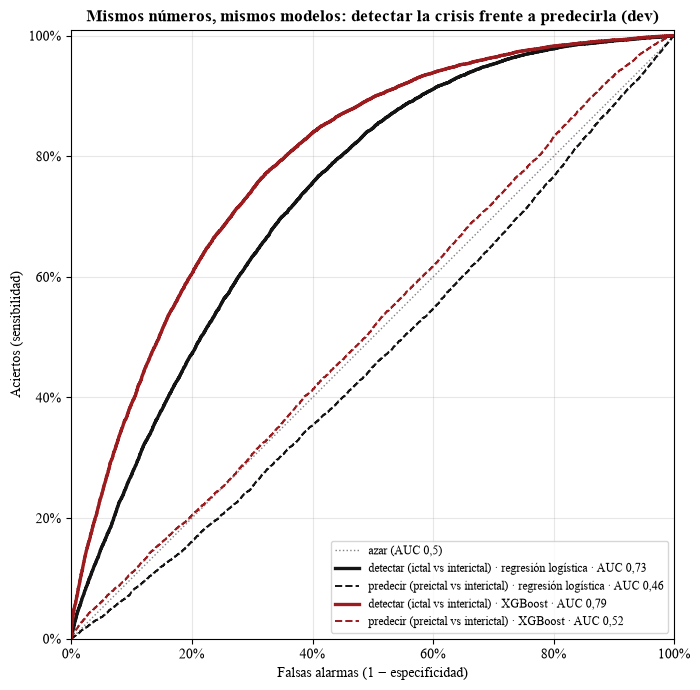

In [27]:
# Figura: la misma curva ROC para detectar (continua) y para predecir (discontinua)
with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(7.5, 7))
    ax.plot([0, 1], [0, 1], color='gray', lw=1, ls=':', label='azar (AUC 0,5)')

    # 1) Dos curvas por modelo: detectar y predecir
    for nombre in MODELOS:
        auc_d = float(deteccion.loc[NOMBRES_MODELO[nombre], '_auc_deteccion'])
        fpr, tpr, _ = roc_curve(y_det_v, puntuaciones_det[nombre])
        ax.plot(fpr, tpr, color=ESTILO_MODELO[nombre], lw=2.4,
                label=f'detectar (ictal vs interictal) · {NOMBRES_MODELO[nombre]} · AUC {decimal(auc_d)}')

        clave = mejores[(nombre, 'normal')]
        fpr, tpr, _ = roc_curve(y[validar], puntuaciones[clave][validar])
        ax.plot(fpr, tpr, color=ESTILO_MODELO[nombre], lw=1.4, ls='--',
                label=f'predecir (preictal vs interictal) · {NOMBRES_MODELO[nombre]} · AUC {decimal(nota.loc[(NOMBRES_MODELO[nombre], "normal"), "AUC-ROC"])}')

    # 2) Rotular y guardar
    ax.set_xlabel('Falsas alarmas (1 − especificidad)')
    ax.set_ylabel('Aciertos (sensibilidad)')
    ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title('Mismos números, mismos modelos: detectar la crisis frente a predecirla (dev)', fontsize=12, fontweight='bold')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect('equal')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right', fontsize=8.5)
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'deteccion_frente_a_prediccion.png', dpi=150, bbox_inches='tight')
    plt.show()

In [28]:
# Detección por grupo de inicio (⚡ de ese grupo frente a todas las 💤), con el mejor modelo de detección
nombre_det = next(n for n, bonito in NOMBRES_MODELO.items() if bonito == mejor_det)
filas_grupo_det = {}

for grupo in [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(grupo_det_v[y_det_v == 1])]:
    mascara = (y_det_v == 0) | (grupo_det_v == grupo)
    a, i_, s_ = auroc_con_intervalo(y_det_v[mascara], puntuaciones_det[nombre_det][mascara], pac_det_v[mascara],
                                    n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    filas_grupo_det[con_icono(grupo)] = {'pacientes con ⚡': len(set(pac_det_v[(y_det_v == 1) & (grupo_det_v == grupo)])),
                                         '⚡ ictal': int(((y_det_v == 1) & (grupo_det_v == grupo)).sum()),
                                         'detección: AUC-ROC': a,
                                         'IC 95 % (por paciente)': f'{decimal(i_)} – {decimal(s_)}'}

deteccion_grupo = pd.DataFrame(filas_grupo_det).T
deteccion_grupo.index.name = 'grupo de inicio'
if len(deteccion_grupo):
    deteccion_grupo['detección: AUC-ROC'] = deteccion_grupo['detección: AUC-ROC'].astype(float)
    display(Markdown(f'**Detección por grupo de inicio** ({mejor_det})'))
    display(con_separadores(deteccion_grupo, decimales=3))

**Detección por grupo de inicio** (XGBoost)

,pacientes con ⚡,⚡ ictal,detección: AUC-ROC,IC 95 % (por paciente)
grupo de inicio,,,,
♦️ focal,22,6.701,"0,796","0,71 – 0,86"
🔷 generalizada,25,5.713,"0,785","0,73 – 0,85"
🔹 ausencia,4,121,"0,793","0,69 – 0,99"


👀 **Cómo leer la figura y la tabla.** En la figura, cada color es un modelo (negro = regresión logística, rojo = XGBoost). La línea **continua** es detectar la crisis; la **discontinua**, predecirla. Cuanto más se separa una curva de la diagonal de puntos (el azar), mejor. La tabla repite la detección separando las ⚡ por grupo de inicio.

✅ **Qué deberías ver:** las continuas muy por encima de las discontinuas. Esa distancia es el mensaje para la memoria: *con la misma información, la crisis se **ve** cuando está ocurriendo, pero no se **anuncia** en los 4 s sueltos de antes*. Para predecir hará falta algo más: más contexto que 4 s, comparar a cada paciente consigo mismo (las dos cosas las prueba **F03.03**) o una red que vea la onda entera (F03.04).

## 10. El resultado → modelos, tablas y `configuracion.json`

Se guardan los dos modelos finales, las tablas y las puntuaciones de cada ventana de 🟡 dev. F03.04 las leerá para comparar la red con la línea base **ventana a ventana** y con las mismas métricas.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">finales</code> · modelo → (modelo final entrenado, su prueba) <i style="color:#4d4d4d">(§8)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">rejilla, nota, por_paciente, por_grupo, deteccion, importancia</code> · las tablas de §4 a §9 <i style="color:#4d4d4d">(§4-§9)</i></li></ul></div>

In [29]:
# Modelos finales (uno por modelo, con sus mejores hiperparámetros y variante)
(RUTA_RESULTADOS / 'modelos').mkdir(exist_ok=True)
filas_modelos = {}

for nombre, (modelo, clave) in finales.items():
    ruta = RUTA_RESULTADOS / 'modelos' / f'{CONJUNTO}_{nombre}.joblib'
    joblib.dump(modelo, ruta)
    filas_modelos[NOMBRES_MODELO[nombre]] = {'fichero': f'modelos/{ruta.name}', 'variante': clave[1],
                                             'hiperparámetros': clave[2], 'KB': ruta.stat().st_size / 1e3}

tabla_modelos = pd.DataFrame(filas_modelos).T
tabla_modelos.index.name = 'modelo'
display(Markdown('💾 **Modelos guardados** (`joblib`): se cargan con `joblib.load(ruta)` y puntúan con `modelo.predict_proba(X)[:, 1]`.'))
display(con_separadores(tabla_modelos, decimales=0))

💾 **Modelos guardados** (`joblib`): se cargan con `joblib.load(ruta)` y puntúan con `modelo.predict_proba(X)[:, 1]`.

,fichero,variante,hiperparámetros,KB
modelo,,,,
regresión logística,modelos/general_logistica.joblib,mismo_peso_paciente,"C = 0,01",5
XGBoost,modelos/general_xgboost.joblib,mismo_peso_paciente,"max_depth = 3 · n_estimators = 300 · learning_rate = 0,05",360


In [30]:
# 1) La rejilla y la nota de cada modelo
rejilla.reset_index().to_csv(RUTA_RESULTADOS / 'rejilla.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'rejilla.csv', 'una fila por prueba (modelo, variante e hiperparámetros) con su AUC-ROC en 🟡 dev')

(nota.drop(columns=['_inferior', '_superior'])
     .assign(ic_inferior=nota._inferior, ic_superior=nota._superior)
     .reset_index()
     .to_csv(RUTA_RESULTADOS / 'resultados_dev.csv', index=False))
mostrar_fichero(RUTA_RESULTADOS / 'resultados_dev.csv', 'la nota de cada modelo y variante con sus mejores hiperparámetros: AUC-ROC con su '
                'intervalo, sensibilidad con especificidad fija y AUC por paciente')

# 2) Por paciente y por grupo
por_paciente.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_paciente_dev.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'auc_por_paciente_dev.csv', 'una fila por paciente de 🟡 dev con AUC propia: la de la referencia, '
                'sus ventanas y la de la otra variante')
if len(por_grupo):
    por_grupo.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_grupo_dev.csv', index=False)
    mostrar_fichero(RUTA_RESULTADOS / 'auc_por_grupo_dev.csv', 'una fila por grupo de inicio: AUC de la referencia con las ⏳ de ese '
                    'grupo frente a todas las 💤 de 🟡 dev')

# 3) La comprobación de §9 y la importancia de cada característica
deteccion.drop(columns=COLUMNAS_OCULTAS_DET).reset_index().to_csv(RUTA_RESULTADOS / 'deteccion_dev.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'deteccion_dev.csv', 'la comprobación de §9: AUC de cada modelo para predecir (⏳ vs 💤) y '
                'para detectar (⚡ vs 💤) en 🟡 dev')
importancia.to_csv(RUTA_RESULTADOS / 'importancia.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'importancia.csv', 'una fila por característica: peso de la logística (con signo) y ganancia de XGBoost (parte de 1)')

💾 **Guardado `rejilla.csv`** · 1,1 KB · 10 filas × 5 columnas  
*Qué guarda:* una fila por prueba (modelo, variante e hiperparámetros) con su AUC-ROC en 🟡 dev. *Abajo:* las 5 primeras filas.

,modelo,variante,hiperparámetros,AUC-ROC en validación,segundos
0,regresión logística,normal,"C = 0,01",0.463124,0.652529
1,regresión logística,mismo_peso_paciente,"C = 0,01",0.486136,0.624209
2,regresión logística,normal,"C = 0,1",0.464366,0.504516
3,regresión logística,mismo_peso_paciente,"C = 0,1",0.483891,0.621116
4,regresión logística,normal,C = 1,0.464805,0.595952


💾 **Guardado `resultados_dev.csv`** · 896 B · 4 filas × 10 columnas  
*Qué guarda:* la nota de cada modelo y variante con sus mejores hiperparámetros: AUC-ROC con su intervalo, sensibilidad con especificidad fija y AUC por paciente. *Abajo:* las 4 primeras filas.

,modelo,variante,hiperparámetros,AUC-ROC,IC 95 % (por paciente),sensibilidad con especificidad 90 %,AUC por paciente (mediana),pacientes con AUC propia,ic_inferior,ic_superior
0,XGBoost,mismo_peso_paciente,max_depth = 3 · n_estimators = 300 · learning_...,0.523016,"0,47 – 0,57",0.088160,0.538975,30,0.472497,0.570946
1,XGBoost,normal,max_depth = 5 · n_estimators = 300 · learning_...,0.516630,"0,48 – 0,56",0.108746,0.496537,30,0.475646,0.559851
2,regresión logística,mismo_peso_paciente,"C = 0,01",0.486136,"0,45 – 0,56",0.096301,0.559323,30,0.452031,0.558913
3,regresión logística,normal,C = 1,0.464805,"0,42 – 0,53",0.077344,0.532795,30,0.419772,0.529606


💾 **Guardado `auc_por_paciente_dev.csv`** · 1,8 KB · 30 filas × 5 columnas  
*Qué guarda:* una fila por paciente de 🟡 dev con AUC propia: la de la referencia, sus ventanas y la de la otra variante. *Abajo:* las 5 primeras filas.

,paciente,auroc,⏳ preictal,💤 interictal,auroc (normal)
0,aaaaamva,0.257893,58,1800,0.359291
1,aaaaaovm,0.270479,116,1800,0.343693
2,aaaaamta,0.325823,58,401,0.462250
3,aaaaaexe,0.361686,174,15,0.355556
4,aaaaamnd,0.369138,58,1800,0.376245


... (2 outputs left out)

💾 **Guardado `deteccion_dev.csv`** · 392 B · 2 filas × 6 columnas  
*Qué guarda:* la comprobación de §9: AUC de cada modelo para predecir (⏳ vs 💤) y para detectar (⚡ vs 💤) en 🟡 dev. *Abajo:* las 2 primeras filas.

,modelo,predicción ⏳ vs 💤 (§5),detección ⚡ vs 💤,detección: sensibilidad con especificidad 90 %,detección: AUC por paciente (mediana),detección: pacientes con AUC propia
0,regresión logística,"0,46 [0,42 – 0,53]","0,73 [0,68 – 0,79]",0.271799,0.764525,36
1,XGBoost,"0,52 [0,48 – 0,56]","0,79 [0,74 – 0,84]",0.389868,0.775638,36


💾 **Guardado `importancia.csv`** · 7,5 KB · 110 filas × 4 columnas  
*Qué guarda:* una fila por característica: peso de la logística (con signo) y ganancia de XGBoost (parte de 1). *Abajo:* las 5 primeras filas.

,característica,peso logística,ganancia XGBoost,dirección (logística)
0,FP1-F7 · delta,0.074546,0.008970,⏳ más preictal
1,FP1-F7 · theta,-0.086257,0.005682,💤 más interictal
2,FP1-F7 · alfa,0.094846,0.008523,⏳ más preictal
3,FP1-F7 · beta,-0.144438,0.009152,💤 más interictal
4,FP1-F7 · gamma,0.210237,0.008547,⏳ más preictal


In [31]:
# Puntuaciones de cada ventana de validación (para comparar con la red en F03.04, ventana a ventana)
puntos = filas.loc[validar, ['id_ventana', 'split', 'patient', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
for (nombre, variante), clave in mejores.items():
    puntos[f'puntuacion_{nombre}_{variante}'] = puntuaciones[clave][validar].round(5)

puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de validación: quién es, su clase y la puntuación (0-1) '
                'de cada modelo y variante. F03.04 la usa para comparar la red con la línea base')

💾 **Guardado `puntuaciones_validacion.csv`** · 6,4 MB · 55.879 filas × 11 columnas  
*Qué guarda:* una fila por ventana de validación: quién es, su clase y la puntuación (0-1) de cada modelo y variante. F03.04 la usa para comparar la red con la línea base. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,clase,etiqueta,grupo,crisis_id,puntuacion_xgboost_mismo_peso_paciente,puntuacion_xgboost_normal,puntuacion_logistica_mismo_peso_paciente,puntuacion_logistica_normal
0,aaaaaajy_s003_t004_interictal_000000000_000003072,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.47777,0.63110,0.60033,0.65415
1,aaaaaajy_s003_t004_interictal_000000000_000004096,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.54016,0.63053,0.74508,0.72998
2,aaaaaajy_s003_t004_interictal_000000000_000005120,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.50063,0.43032,0.68864,0.68772
3,aaaaaajy_s003_t004_interictal_000000000_000006144,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.55405,0.59158,0.72784,0.62673
4,aaaaaajy_s003_t004_interictal_000000000_000007168,🟡 dev,aaaaaajy,💤 interictal,0,nan,NaN,0.68641,0.48251,0.62249,0.47964


In [32]:
# configuracion.json: lo que F03.03 y F03.04 leen de este notebook
config = {
    'conjunto': CONJUNTO,
    'splits_usados': SPLITS,
    'eval_usado': False,
    'rondas_validacion': [n for n, _, _ in rondas],
    'caracteristicas': {'tipo': 'log10 de la potencia relativa por banda y canal (Welch)', 'segmento_welch_s': SEGMENTO_S,
                        'bandas_hz': BANDAS_HZ, 'n': len(NOMBRES)},
    'modelos': {nombre: {'variante': clave[1], 'hiperparametros': hiperparametros[clave],
                         'auc_dev': float(nota.loc[(NOMBRES_MODELO[nombre], clave[1]), 'AUC-ROC'])}
                for nombre, (_, clave) in finales.items()},
    'referencia': {'modelo': nombre_ref, 'variante': variante_ref, 'hiperparametros': hiperparametros[clave_ref],
                   'auc_dev': float(auc_ref), 'ic95_dev': [float(inf_ref), float(sup_ref)]},
    'comprobacion_deteccion': {'modelo': nombre_det, 'auc_dev': auc_det, 'ic95_inferior': inf_det, 'veredicto': veredicto[0]},
    'especificidad': ESPECIFICIDAD,
    'n_bootstrap': N_BOOTSTRAP,
    'semilla': SEMILLA,
    'versiones': versiones_usadas,
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=4), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la configuración y la nota de la línea base, para que F03.04 la lea y compare la red con ella')

💾 **Guardado `configuracion.json`** · 2,2 KB · 13 claves  
*Qué guarda:* la configuración y la nota de la línea base, para que F03.04 la lea y compare la red con ella. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
splits_usados,"[""train"", ""dev""]"
eval_usado,false
rondas_validacion,"[""🟡 dev""]"
caracteristicas,"{""tipo"": ""log10 de la potencia relativa por banda y canal (Welch)"", ""segmento_welch_s"": 1.…"
modelos,"{""logistica"": {""variante"": ""mismo_peso_paciente"", ""hiperparametros"": {""C"": 0.01}, ""auc_dev…"
referencia,"{""modelo"": ""xgboost"", ""variante"": ""mismo_peso_paciente"", ""hiperparametros"": {""max_depth"": …"
comprobacion_deteccion,"{""modelo"": ""xgboost"", ""auc_dev"": 0.7909272433581985, ""ic95_inferior"": 0.7367743197181571, …"
especificidad,0.9


## 11. Resumen → `summary.txt`

In [33]:
# 1) Las cifras clave, una por línea
datos = [
    f'Línea base: {config["fecha"]} · conjunto {CONJUNTO} · semilla {SEMILLA}' + ('  ·  MODO PRUEBA (F03.01 incompleto)' if config_01.get('modo_prueba') else ''),
    f'Características: {len(NOMBRES)} por ventana (log10 de la potencia relativa, {len(CANALES_TCP)} canales × {len(BANDAS)} bandas, '
    f'Welch de {numero_legible(SEGMENTO_S)} s)',
    f'Entrenamiento: {numero_legible(int(filas.en_entrenamiento.sum()))} ventanas · validación: {numero_legible(int(validar.sum()))} ventanas '
    f'({", ".join(n for n, _, _ in rondas)}) · 🟢 eval no usado',
    f'Referencia: {modelo_ref} · {variante_ref} ({clave_ref[2]}) → AUC-ROC en dev {con_intervalo(auc_ref, inf_ref, sup_ref)}',
    f'AUC por paciente (mediana): {decimal(por_paciente.auroc.median())} · {numero_legible(round(100 * (por_paciente.auroc > 0.5).mean()))} % de los '
    f'{len(por_paciente)} pacientes por encima del azar',
    f'Comprobación (§9): detectar ⚡ frente a 💤 con los mismos números → {mejor_det} AUC {con_intervalo(auc_det, inf_det, sup_det)} · {veredicto[0]}',
]

# 2) Las tablas
tablas_resumen = {'Nota en dev': nota.drop(columns=['_inferior', '_superior']).round(3),
                  'Rejilla': rejilla.round(3),
                  'Por paciente (resumen)': resumen_paciente.round(3),
                  'Por grupo de inicio': por_grupo,
                  'Comprobación: detección frente a predicción': deteccion.drop(columns=COLUMNAS_OCULTAS_DET),
                  'Las 10 características más usadas': top.round(3)}

# 3) Escribir y enseñar
texto = ('=== F03.02 · Línea base ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items() if len(tabla)) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen de la línea base en texto, para consultarlo sin abrir el notebook')

💾 **Guardado `summary.txt`** · 6,4 KB · 61 líneas  
*Qué guarda:* el resumen de la línea base en texto, para consultarlo sin abrir el notebook. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== F03.02 · Línea base ===
2,Línea base: 2026-11-17 13:06 · conjunto general · semilla 42
3,"Características: 110 por ventana (log10 de la potencia relativa, 22 canales × 5 bandas, Welch de 1 s)"
4,Entrenamiento: 29.152 ventanas · validación: 55.879 ventanas (🟡 dev) · 🟢 eval no usado
5,"Referencia: XGBoost · mismo_peso_paciente (max_depth = 3 · n_estimators = 300 · learning_rate = 0,05) → AUC-ROC en dev 0,52 [0,47 – 0,57]"


## 12. Conclusiones

Primero, de un vistazo: dónde cae cada nota en **la regla de la AUC**. Después, las conclusiones, que se escriben solas a partir de los datos.

<div style="background:#eaf7ea; border:1px solid #a9d8a9; border-left:6px solid #3d9a3d; border-radius:6px; padding:8px 14px; color:#1a1a1a;"><b style="color:#1a1a1a">📦 Variables de celdas anteriores que se usan aquí</b><ul style="margin:6px 0 2px 0; padding-left:20px; color:#1a1a1a"><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_ref, inf_ref, sup_ref</code> · la nota de predecir (referencia) y su intervalo <i style="color:#4d4d4d">(§5)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">auc_det, inf_det, sup_det</code> · la nota de detectar (mejor modelo) y su intervalo <i style="color:#4d4d4d">(§9)</i></li><li style="color:#1a1a1a; margin:2px 0"><code style="background:#d3edd3; color:#1a1a1a; padding:0 4px; border-radius:3px">por_paciente</code> · la AUC de cada paciente (se dibuja su mediana) <i style="color:#4d4d4d">(§6)</i></li></ul></div>

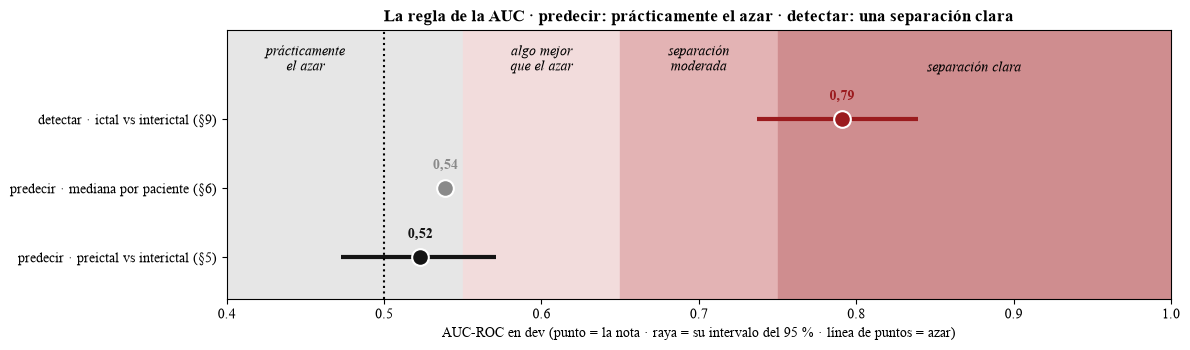

In [34]:
def calificar(auc):
    """La zona de la regla de la AUC en la que cae una nota (las mismas zonas que ZONAS_AUC)."""
    if auc < 0.55:
        return 'prácticamente el azar'
    if auc < 0.65:
        return 'algo mejor que el azar'
    if auc < 0.75:
        return 'una separación moderada'
    return 'una separación clara'


# 1) Las zonas de la regla (las mismas que usa calificar() y las conclusiones de abajo)
ZONAS_AUC = [(0.00, 0.55, 'prácticamente\nel azar', '#e6e6e6'),
             (0.55, 0.65, 'algo mejor\nque el azar', '#f2dcdc'),
             (0.65, 0.75, 'separación\nmoderada', '#e3b3b4'),
             (0.75, 1.00, 'separación clara', '#cf8d8f')]
marcas = [('predecir · preictal vs interictal (§5)', auc_ref, inf_ref, sup_ref, COLORES_ESQUEMA['negro']),
          ('predecir · mediana por paciente (§6)', float(por_paciente.auroc.median()), None, None, COLORES_ESQUEMA['gris']),
          ('detectar · ictal vs interictal (§9)', auc_det, inf_det, sup_det, COLORES_ESQUEMA['rojo'])]

with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(12, 3.6))

    # 2) Dibujar las zonas de fondo con su nombre
    for desde, hasta, nombre_zona, color in ZONAS_AUC:
        ax.axvspan(desde, hasta, color=color, zorder=0)
        x_texto = 0.45 if desde < 0.5 else (desde + hasta) / 2     # la primera, a la izquierda de la raya del azar
        ax.text(x_texto, len(marcas) - 0.35, nombre_zona, ha='center', va='bottom', fontsize=10, style='italic')

    # 3) Una fila por nota: el punto y, si tiene, su intervalo
    for fila_y, (etiqueta, valor, inferior, superior, color) in enumerate(marcas):
        if inferior is not None:
            ax.plot([inferior, superior], [fila_y, fila_y], color=color, lw=3, solid_capstyle='butt')
        ax.plot(valor, fila_y, 'o', color=color, ms=12, mec='white', mew=1.5, zorder=3)
        ax.text(valor, fila_y + 0.28, decimal(valor), ha='center', fontsize=10, fontweight='bold', color=color)
    ax.axvline(0.5, color='black', ls=':', lw=1.5)

    # 4) Rotular y guardar
    ax.set_yticks(range(len(marcas)), [m[0] for m in marcas])
    ax.set_ylim(-0.6, len(marcas) + 0.3)
    ax.set_xlim(min(0.40, min(m[2] or m[1] for m in marcas) - 0.02), 1.0)
    ax.set_xlabel('AUC-ROC en dev (punto = la nota · raya = su intervalo del 95 % · línea de puntos = azar)')
    ax.set_title(f'La regla de la AUC · predecir: {calificar(auc_ref)} · detectar: {calificar(auc_det)}', fontsize=12, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'regla_auc.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** El fondo divide la AUC en cuatro zonas, de *prácticamente el azar* (gris) a *separación clara* (rojo más oscuro). Cada fila es una nota de este notebook: el punto es la nota y la raya, su intervalo. Abajo, **predecir** (la referencia de §5); en medio, la **mediana por paciente** de §6; arriba, **detectar** (§9). La distancia entre la fila de predecir y la de detectar es el mensaje del notebook. El título dice en qué zona cae cada una (sale de los datos).

In [35]:
# 1) Las cifras que necesitan las conclusiones
ic_cruza = inf_ref <= 0.5
auc_log, auc_xgb = (nota.loc[NOMBRES_MODELO[n], 'AUC-ROC'].max() for n in ['logistica', 'xgboost'])
fila_log = nota.loc[NOMBRES_MODELO['logistica']].loc[nota.loc[NOMBRES_MODELO['logistica'], 'AUC-ROC'].idxmax()]
fila_xgb = nota.loc[NOMBRES_MODELO['xgboost']].loc[nota.loc[NOMBRES_MODELO['xgboost'], 'AUC-ROC'].idxmax()]
se_solapan = not (fila_log['_superior'] < fila_xgb['_inferior'] or fila_xgb['_superior'] < fila_log['_inferior'])

efecto_peso = {n: float(nota.loc[(NOMBRES_MODELO[n], 'mismo_peso_paciente'), 'AUC-ROC'] - nota.loc[(NOMBRES_MODELO[n], 'normal'), 'AUC-ROC'])
               for n in MODELOS}
medianas_variante = {variante_ref: float(por_paciente.auroc.median()),
                     otra_variante: float(por_paciente[f'auroc ({otra_variante})'].median())}
efecto_mediana = medianas_variante['mismo_peso_paciente'] - medianas_variante['normal']
mediana_paciente = float(por_paciente.auroc.median())
brecha = auc_ref - mediana_paciente
top3 = [f'{c} ({"⏳" if importancia.set_index("característica").loc[c, "peso logística"] > 0 else "💤"})' for c in top.index[:3]]

# 2) Las conclusiones, una por punto
conclusiones = [
    f'**1. La línea base consigue {calificar(auc_ref)}: AUC-ROC {con_intervalo(auc_ref, inf_ref, sup_ref)} en 🟡 dev** '
    f'({modelo_ref}, variante {variante_ref}). '
    + ('🔴 El intervalo incluye el 0,5: con estos pacientes no se puede asegurar que sea mejor que el azar.' if ic_cruza else
       'El intervalo entero queda por encima de 0,5: aprende algo de verdad, incluso con pacientes que no ha visto.'),

    f'**2. Logística {decimal(auc_log)} frente a XGBoost {decimal(auc_xgb)}.** '
    + ('Sus intervalos se solapan: con estos datos no hay un ganador claro, y el modelo más sencillo (la logística) explica lo mismo.' if se_solapan else
       f'La diferencia sale fuera de los intervalos: {"XGBoost" if auc_xgb > auc_log else "la logística"} es mejor de verdad'
       + (' (las combinaciones de características ayudan).' if auc_xgb > auc_log else ' (las combinaciones de XGBoost no ayudan; puede estar sobreajustando).')),

    '**3. Mismo peso por paciente** (frente a la variante normal): cambia la AUC global en '
    + ', '.join(NOMBRES_MODELO[n] + ' ' + con_signo(d) for n, d in efecto_peso.items())
    + f' y la mediana de la AUC por paciente de {modelo_ref} en {con_signo(efecto_mediana)}. '
    + ('Ayuda poco o nada: el desequilibrio entre pacientes de F03.01 §3.1 no parece pesar en la línea base.' if max(abs(d) for d in efecto_peso.values()) < 0.01 else
       'Se nota: merece la pena repetir el experimento con la red (WeightedRandomSampler) en F03.04.'),

    f'**4. Por paciente, la mediana es {decimal(mediana_paciente)}** ({numero_legible(round(100 * (por_paciente.auroc > 0.5).mean()))} % de los '
    f'{len(por_paciente)} pacientes por encima del azar). '
    + (f'🟡 Queda {decimal(brecha)} por debajo de la AUC global: parte de la nota global viene de distinguir pacientes, no ventanas '
       '(el modelo tramposo de §6). En F03.04 dar siempre las dos cifras.' if brecha > 0.05 else
       f'🟡 Queda {decimal(-brecha)} por encima de la AUC global: dentro de cada paciente ordena bien las ventanas, pero las puntuaciones '
       'no son comparables entre pacientes (unos puntúan alto en todo y otros bajo). Un mismo umbral no valdría para todos: '
       'a tener en cuenta en la evaluación en continuo (umbral por paciente o normalizar las puntuaciones).' if brecha < -0.05 else
       'Está cerca de la AUC global: la nota no viene de reconocer pacientes.'),

    (f'**5. Por grupo de inicio:** ' + ', '.join(f'{g} {decimal(f["AUC-ROC"])} ({f["pacientes con ⏳"]} pac.)' for g, f in por_grupo.iterrows())
     + f'. El que mejor se predice es {por_grupo["AUC-ROC"].idxmax()} y el que peor, {por_grupo["AUC-ROC"].idxmin()}. '
     + ('Con tan pocos pacientes en algún grupo, la comparación es orientativa. ' if por_grupo['pacientes con ⏳'].min() < 5 else '')
     + 'Es un primer argumento para probar después modelos por grupo.') if len(por_grupo) else
    '**5. Por grupo de inicio:** no se ha podido separar (las ventanas no traen el grupo).',

    f'**6. Qué usa:** las tres características que más usan los dos modelos son {", ".join(top3)} '
    '(⏳ = cuanto más parte de la energía ahí, más preictal; 💤 = al revés). Comparar con lo que mire la red en F03.04 y en la Fase 5.',

    f'**7. Comprobación de la cadena (§9): {veredicto[0]}.** Detectar la crisis con los mismos números da AUC {decimal(auc_det)} '
    f'frente a {decimal(auc_ref)} al predecirla. '
    + ('La información está en los datos cuando la crisis ocurre, pero 4 s sueltos de antes no la anuncian. F03.03 prueba si el último minuto '
       'y la comparación con cada paciente aportan lo que falta.' if auc_det >= 0.75 else 'Hay que entender por qué antes de seguir (ver el recuadro de §9).'),

    f'**8. Para F03.04:** la red tiene que superar **AUC-ROC {decimal(auc_ref)}** en 🟡 dev (y la mediana por paciente de {decimal(mediana_paciente)}), '
    'con las mismas ventanas y las mismas métricas. 🟢 eval y los controles de F02.05 siguen sin tocar: se usan una sola vez, al final de la fase.',
]
display(Markdown('\n\n'.join(conclusiones)))

**1. La línea base consigue prácticamente el azar: AUC-ROC 0,52 [0,47 – 0,57] en 🟡 dev** (XGBoost, variante mismo_peso_paciente). 🔴 El intervalo incluye el 0,5: con estos pacientes no se puede asegurar que sea mejor que el azar.

**2. Logística 0,49 frente a XGBoost 0,52.** Sus intervalos se solapan: con estos datos no hay un ganador claro, y el modelo más sencillo (la logística) explica lo mismo.

**3. Mismo peso por paciente** (frente a la variante normal): cambia la AUC global en regresión logística +0,021, XGBoost +0,006 y la mediana de la AUC por paciente de XGBoost en +0,042. Se nota: merece la pena repetir el experimento con la red (WeightedRandomSampler) en F03.04.

**4. Por paciente, la mediana es 0,54** (57 % de los 30 pacientes por encima del azar). Está cerca de la AUC global: la nota no viene de reconocer pacientes.

**5. Por grupo de inicio:** ♦️ focal 0,53 (20 pac.), 🔷 generalizada 0,51 (16 pac.), 🔹 ausencia 0,56 (3 pac.). El que mejor se predice es 🔹 ausencia y el que peor, 🔷 generalizada. Con tan pocos pacientes en algún grupo, la comparación es orientativa. Es un primer argumento para probar después modelos por grupo.

**6. Qué usa:** las tres características que más usan los dos modelos son A1-T3 · gamma (⏳), CZ-C4 · gamma (💤), P4-O2 · gamma (⏳) (⏳ = cuanto más parte de la energía ahí, más preictal; 💤 = al revés). Comparar con lo que mire la red en F03.04 y en la Fase 5.

**7. Comprobación de la cadena (§9): ✅ La cadena de datos funciona.** Detectar la crisis con los mismos números da AUC 0,79 frente a 0,52 al predecirla. La información está en los datos cuando la crisis ocurre, pero 4 s sueltos de antes no la anuncian. F03.03 prueba si el último minuto y la comparación con cada paciente aportan lo que falta.

**8. Para F03.04:** la red tiene que superar **AUC-ROC 0,52** en 🟡 dev (y la mediana por paciente de 0,54), con las mismas ventanas y las mismas métricas. 🟢 eval y los controles de F02.05 siguen sin tocar: se usan una sola vez, al final de la fase.

## 13. Qué nos ha enseñado este notebook (y por qué cambió el plan)

> 🎯 **Para qué:** dejar escrito, con los datos de esta ejecución, el razonamiento que llevó a la fase por el camino que siguió. Es la parte del notebook que más se usará en la **memoria**.

![De las pistas a la decisión](img/de_pistas_a_decision.png)

👀 **Qué enseña.** Las tres pistas de este notebook se suman: ① predecir con 4 s sueltos sale casi el azar; ② con los **mismos** números la crisis **sí** se detecta, así que los datos están bien; ③ cada paciente parece tener su propio "nivel". Juntas llevan a una conclusión: **falta información, no potencia**. Por eso la fase siguió por F03.03 (contexto y normalización por paciente) antes de la red. El recuadro de abajo da las cifras de esta ejecución.

In [36]:
# 1) Las tres pistas, con su cifra de esta ejecución
auc_mediana_max = float(nota['AUC por paciente (mediana)'].max())
auc_global_max = float(nota['AUC-ROC'].max())
pistas = [
    ('1 · La línea base', f'AUC {con_intervalo(auc_ref, inf_ref, sup_ref)}',
     'casi el azar' if inf_ref <= 0.5 else 'por encima del azar',
     'Una ventana de 4 s sola, resumida en 110 números, apenas distingue el minuto antes de una crisis en pacientes nuevos.' if inf_ref <= 0.5 else
     'Una ventana de 4 s sola ya distingue algo el minuto antes de una crisis en pacientes nuevos.'),
    ('2 · La comprobación (§9)', f'detección AUC {decimal(auc_det)}', veredicto[0],
     'Con los mismos números la crisis sí se reconoce mientras ocurre: los datos y las etiquetas están bien.' if auc_det >= 0.75 else
     'Ni siquiera la detección funciona bien: hay que revisar la cadena de datos.'),
    ('3 · La pista (§6)', f'AUC por paciente {decimal(auc_mediana_max)} frente a global {decimal(auc_global_max)}',
     'dentro de cada paciente ordena algo mejor' if auc_mediana_max > auc_global_max else 'sin pista clara',
     'Cada paciente parece tener su propio "nivel": comparar a cada uno consigo mismo podría ayudar.'),
]
tabla_pistas = pd.DataFrame(pistas, columns=['qué', 'cifra', 'lectura', 'qué significa']).set_index('qué')

# 2) La decisión que se tomó con ellas
if auc_det >= 0.75 and inf_ref <= 0.55:
    plan = ('Por eso, antes de la red, se añadió F03.03: se prueba si mirar el último minuto (contexto) y comparar a cada paciente '
            'consigo mismo (normalización por paciente) dan a los modelos clásicos lo que les falta. La red pasó a ser F03.04 y hereda lo que '
            'decida F03.03.')
elif auc_det >= 0.75:
    plan = 'La línea base ya predice algo: la red (F03.04) parte de aquí, y F03.03 estudia si el contexto y la normalización por paciente lo mejoran.'
else:
    plan = 'Antes de seguir hay que revisar la cadena de datos de la Fase 2 (F02.03, F02.04) y F03.01.'

mostrar_destacado('Lo que nos ha enseñado F03.02', plan, tabla_pistas)

,cifra,lectura,qué significa
qué,,,
1 · La línea base,"AUC 0,52 [0,47 – 0,57]",casi el azar,"Una ventana de 4 s sola, resumida en 110 números, apenas distingue el minuto antes de una crisis en pacientes nuevos."
2 · La comprobación (§9),"detección AUC 0,79",✅ La cadena de datos funciona,Con los mismos números la crisis sí se reconoce mientras ocurre: los datos y las etiquetas están bien.
3 · La pista (§6),"AUC por paciente 0,56 frente a global 0,52",dentro de cada paciente ordena algo mejor,"Cada paciente parece tener su propio ""nivel"": comparar a cada uno consigo mismo podría ayudar."


👀 **Cómo leer el recuadro.** Las tres pistas que dejó este notebook, con su cifra de esta ejecución, y la decisión que se tomó con ellas. La historia completa de la fase está en la imagen del principio (`img/historia_fase_03_nb02.png`).

> 📝 **Para la memoria.** Esta es la frase clave: *con los mismos datos y los mismos modelos, la crisis se **detecta** bien pero no se **predice** desde una ventana de 4 s*. Justifica todo lo que viene después: no basta con un modelo más potente, hace falta **otra información** (más contexto y a cada paciente frente a sí mismo).

## 14. Archivos generados y siguiente paso

En `outputs/fase_03/<CONJUNTO>/02_linea_base/` (con `CONJUNTO = general`, `outputs/fase_03/general/02_linea_base/`):

- `modelos/<CONJUNTO>_logistica.joblib` y `<CONJUNTO>_xgboost.joblib`: los dos modelos finales.
- `rejilla.csv`: todas las pruebas de hiperparámetros y variantes, con su AUC en dev.
- `resultados_dev.csv`: la nota de cada modelo y variante (AUC con intervalo, sensibilidad, AUC por paciente).
- `auc_por_paciente_dev.csv` y `auc_por_grupo_dev.csv`: la nota por paciente y por grupo de inicio.
- `deteccion_dev.csv`: la comprobación de §9 (detectar frente a predecir).
- `importancia.csv`: qué peso da cada modelo a cada característica.
- `puntuaciones_validacion.csv`: la puntuación de cada ventana de dev, para compararla con la red.
- `configuracion.json` y `summary.txt`.
- `figuras/`: `bandas_preictal_interictal.png`, `bootstrap_auc_dev.png`, `curvas_roc_dev.png`, `puntuaciones_dev.png`, `auc_por_paciente_dev.png`, `que_ha_aprendido.png`, `deteccion_frente_a_prediccion.png`, `regla_auc.png`.

Compartidos con otros notebooks (no van en la carpeta del conjunto):

- `outputs/fase_03/02_linea_base/caracteristicas/<CONJUNTO>/<split>.npy` y `<split>_ids.csv`: los 110 números de cada ventana de 🔵 train y 🟡 dev (se reutilizan si los paquetes no cambian). F03.03 los vuelve a usar.
- `outputs/fase_03/01_datos_red/paquetes/ictal/` y `outputs/fase_03/02_linea_base/caracteristicas/ictal/`: las ventanas ⚡ ictales de 🔵 train y 🟡 dev empaquetadas, con sus características (las reutilizará la Fase 4).

**Siguiente paso → F03.03 (contexto y normalización por paciente).** Con los mismos modelos y características de aquí, prueba si mirar el último minuto y comparar a cada paciente consigo mismo arreglan la predicción. Después llega la red (**F03.04**), que se comparará con esta línea base y con lo mejor de F03.03, con las mismas métricas.